# SMAI Assignment 3, Part 2: SecureVision, Face Compression and Recognition with PCA

**Student username:** `anagha.prajapati`  (institute e-mail `anagha.prajapati@students.iiit.ac.in`)

This notebook builds an eigenface pipeline for the Olivetti faces data set.

* **PCA is implemented from scratch with NumPy** (`PCAFromScratch`, with both the direct covariance method and the Gram-matrix trick). `sklearn.decomposition.PCA` is not used anywhere.
* The image transformations (rotation with bilinear interpolation, Gaussian noise, illumination gradient), the stratified split, the MSE and the compression ratio are also written from scratch.
* `sklearn` is used only for the recognition classifier (`KNeighborsClassifier`), which the assignment allows.
* **PCA is always fitted on training data only.** The test set never contributes to the mean face, the components or the explained variance.

**Reproducibility.** The personalised seed is derived from the username with SHA-256. One generator, `np.random.default_rng(SEED)`, is created once and used in a fixed order for every random choice (split, displayed faces, noise, illumination strengths). All transformed sets are generated once in Section 2.1 and reused unchanged afterwards.

**Plots.** Every figure has the username in its title and is also saved as `figures/anagha.prajapati_2_<name>.png`. Line and bar plots carry the required `plt.text(...)` watermark inside the axes. On figures that consist of face images the watermark is placed in the bottom-right corner of the figure, so that it does not cover the faces.

**Data.** The notebook expects `olivetti_faces.npy` and `olivetti_faces_target.npy` (Kaggle) in `./archive/` (or in the working directory).

**Fixed parameters used throughout** (each is justified where it is introduced):

| parameter | value |
|---|---|
| components for transformed-set experiments | $k_T = 50$ (given) |
| storage formula constants | $N = 320$, $D = 4096$ (given) |
| fill value for pixels uncovered by rotation | 0 (black) |
| interpolation for rotation | bilinear |
| PCA method after Section 2.2 | `gram_trick` |
| classifier | 1-nearest-neighbour, Euclidean distance |

## 0. Setup

In [1]:
import os
import time
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.neighbors import KNeighborsClassifier   # allowed: recognition classifier only

USERNAME = "anagha.prajapati"  # part of the IIITH e-mail before '@'
SEED = int(hashlib.sha256(USERNAME.encode()).hexdigest(), 16) % (2**32)
rng = np.random.default_rng(SEED)   # the single generator used for every random choice below
print(f"username = {USERNAME}")
print(f"SEED     = {SEED}")

K_T = 50                 # number of components for all transformed-set experiments (given)
N_STORE, D_STORE = 320, 4096   # constants of the storage formula (given)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

BLUE, ORANGE, AQUA, YELLOW, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#4a3aa7"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": INK2, "ytick.color": INK2, "lines.linewidth": 2, "lines.markersize": 7,
    "legend.frameon": False, "image.cmap": "gray",
})
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)


def titled(ax, text):
    """Axis title that always contains the username."""
    ax.set_title(f"{text}\n({USERNAME})")


def finish(fig, name, tight=True, hspace=None):
    """Add the username watermark, save as figures/<username>_2_<name>.png and show.
    Chart axes get the watermark inside the axes; figures made only of images get it in the figure corner."""
    chart_axes = [ax for ax in fig.axes if not ax.images and ax.get_label() != "twin"]
    for ax in chart_axes:
        ax.text(0.95, 0.95, USERNAME, ha="right", va="top", transform=ax.transAxes,
                fontsize=10, color="gray", alpha=0.7)
    if not chart_axes:
        fig.text(0.995, 0.005, USERNAME, ha="right", va="bottom", fontsize=10, color="gray", alpha=0.7)
    if tight:
        fig.tight_layout()
    if hspace is not None:
        fig.subplots_adjust(hspace=hspace, top=0.87)   # extra room for two-line titles in image grids
    fig.savefig(os.path.join(FIG_DIR, f"{USERNAME}_2_{name}.png"), dpi=130, bbox_inches="tight")
    plt.show()


def show_face(ax, vec_or_img, title=None, vmin=0.0, vmax=1.0):
    ax.imshow(np.asarray(vec_or_img).reshape(64, 64), cmap="gray", vmin=vmin, vmax=vmax)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    if title is not None:
        ax.set_title(title, fontsize=9)


class fmt:
    """Number formatting for result tables: fmt(df).format("{:.4f}", subset=[cols]) or .format({col: spec}).
    Renders as a normal table in the notebook and as plain text everywhere else."""

    def __init__(self, df):
        self.df, self.show_index = df.copy(), True

    def format(self, spec, subset=None):
        specs = spec if isinstance(spec, dict) else {c: spec for c in (subset if subset is not None else self.df.columns)}
        for col, f in specs.items():
            self.df[col] = self.df[col].map(f.format)
        return self

    def hide(self, axis="index"):
        self.show_index = False
        return self

    def _repr_html_(self):
        return self.df.to_html(index=self.show_index)

    def __repr__(self):
        return self.df.to_string(index=self.show_index)

username = anagha.prajapati
SEED     = 2679482985


---
# 2.1 Data and Transformed Test Sets

## 2.1.1 Loading the data

In [2]:
DATA_DIR = next(d for d in ["archive", ".", "data", "../archive"]
                if os.path.exists(os.path.join(d, "olivetti_faces.npy")))
faces = np.load(os.path.join(DATA_DIR, "olivetti_faces.npy")).astype(np.float64)       # (400, 64, 64)
targets = np.load(os.path.join(DATA_DIR, "olivetti_faces_target.npy")).astype(np.int64)  # (400,)

n_images, H, W = faces.shape
identities, images_per_identity = np.unique(targets, return_counts=True)
print(f"number of images      : {n_images}")
print(f"image size            : {H} x {W} pixels  (= {H * W} values per face)")
print(f"number of identities  : {len(identities)}  (labels {identities.min()} .. {identities.max()})")
print(f"images per identity   : min {images_per_identity.min()}, max {images_per_identity.max()}")
print(f"pixel value range     : [{faces.min():.3f}, {faces.max():.3f}],  mean {faces.mean():.3f}")

number of images      : 400
image size            : 64 x 64 pixels  (= 4096 values per face)
number of identities  : 40  (labels 0 .. 39)
images per identity   : min 10, max 10
pixel value range     : [0.000, 1.000],  mean 0.547


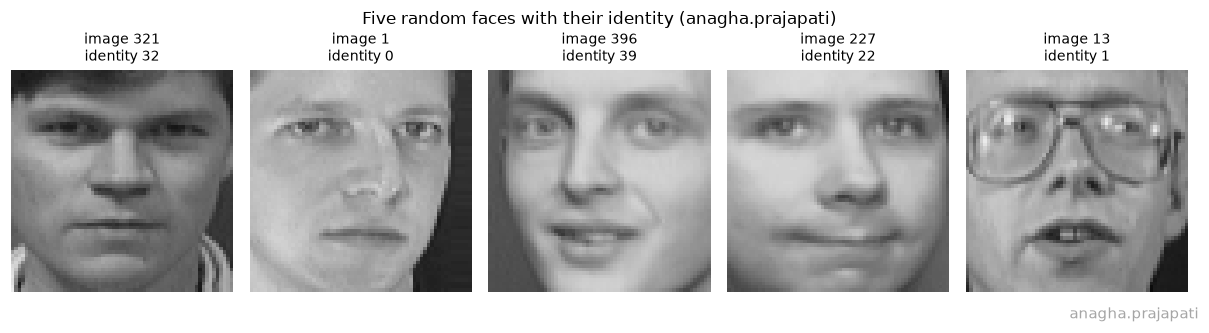

displayed image indices: [321, 1, 396, 227, 13] | identities: [32, 0, 39, 22, 1]


In [3]:
random_idx = rng.choice(n_images, size=5, replace=False)
fig, axes = plt.subplots(1, 5, figsize=(11, 2.9))
for ax, i in zip(axes, random_idx):
    show_face(ax, faces[i], f"image {i}\nidentity {targets[i]}")
fig.suptitle(f"Five random faces with their identity ({USERNAME})", fontsize=11)
finish(fig, "1_random_faces")
print("displayed image indices:", random_idx.tolist(), "| identities:", targets[random_idx].tolist())

The data set has **400 grayscale images of 64 × 64 pixels (4,096 values each) from 40 identities, 10 images per identity**, with pixel values already in [0, 1].

## 2.1.2 Flattening and stratified 80/20 split

Each identity has 10 images. Stratifying by identity therefore puts exactly **8 images of every person in the training set and 2 in the test set**. The split is written from scratch: for each identity the 10 image indices are shuffled with the seeded generator and the first 2 go to the test set.

The images are kept in two forms: as 64 × 64 arrays (needed for the image transformations, which must be applied before flattening) and as flattened 4,096-dimensional vectors (used by PCA and the classifier).

In [4]:
def stratified_split(labels, test_fraction, rng):
    """Return (train_idx, test_idx) with the same fraction of every label in the test set."""
    train_parts, test_parts = [], []
    for c in np.unique(labels):
        idx = rng.permutation(np.flatnonzero(labels == c))
        n_test = int(round(test_fraction * len(idx)))
        test_parts.append(idx[:n_test])
        train_parts.append(idx[n_test:])
    return np.sort(np.concatenate(train_parts)), np.sort(np.concatenate(test_parts))


train_idx, test_idx = stratified_split(targets, 0.20, rng)
assert len(np.intersect1d(train_idx, test_idx)) == 0

img_train, img_test = faces[train_idx], faces[test_idx]          # (N, 64, 64) images
y_train, y_test = targets[train_idx], targets[test_idx]


def flatten(images):
    """(M, 64, 64) images -> (M, 4096) row vectors."""
    return images.reshape(len(images), -1)


X_train, X_test = flatten(img_train), flatten(img_test)
print(f"random seed                : {SEED}")
print(f"X_train shape              : {X_train.shape}   y_train shape: {y_train.shape}")
print(f"X_test  shape              : {X_test.shape}    y_test  shape: {y_test.shape}")
print(f"images per identity (train): {np.unique(np.bincount(y_train)).tolist()}")
print(f"images per identity (test) : {np.unique(np.bincount(y_test)).tolist()}")
N_TRAIN, D = X_train.shape

random seed                : 2679482985
X_train shape              : (320, 4096)   y_train shape: (320,)
X_test  shape              : (80, 4096)    y_test  shape: (80,)
images per identity (train): [8]
images per identity (test) : [2]


## 2.1.3 Transformed test sets

All transformations act on the **64 × 64 images** and are flattened afterwards. All results are clipped to [0, 1].

**Rotation.** Each image is rotated counter-clockwise about its centre, the point $((H-1)/2, (W-1)/2)$, by θ ∈ {0°, 15°, 30°, 45°}. It is implemented from scratch by inverse mapping: for every output pixel we compute where it comes from in the source image and read that location with **bilinear interpolation**.
*Uncovered pixels:* after rotation, the corners of the output have no source pixel (their source location falls outside the image). **We fill them with 0 (black).** Black is a constant, so it adds no invented image content, and it is the usual convention. The consequence is that large rotations create black triangular corners, which is itself a visible change the model has to cope with. θ = 0° reproduces the original image exactly (checked below).

**Gaussian noise.** Independent noise from $\mathcal N(0, \sigma^2)$ is added to every pixel, for σ ∈ {0.05, 0.1, 0.2, 0.5}, and the result is clipped to [0, 1]. Each σ gets its own fixed noise draw.

**Illumination.** Each image is multiplied by a horizontal gradient that rises linearly from $1-s$ at the left edge to $1+s$ at the right edge, with one $s \sim \mathcal U(0.3, 0.9)$ drawn per image, then clipped to [0, 1]. An illuminated copy is made of the test set **and** of the training set.

Every set is generated **once**, in the cell below, and stored in the dictionaries `X_rot`, `X_noise` and the arrays `X_test_illum`, `X_train_illum`. Later sections only read them.

In [5]:
def rotate_image(img, angle_deg, fill=0.0):
    """Rotate a 2-D image counter-clockwise about its centre (bilinear interpolation, constant fill)."""
    h, w = img.shape
    cy, cx = (h - 1) / 2.0, (w - 1) / 2.0
    theta = np.deg2rad(angle_deg)
    cos_t, sin_t = np.cos(theta), np.sin(theta)
    yy, xx = np.mgrid[0:h, 0:w].astype(np.float64)
    dx, dy = xx - cx, yy - cy
    # inverse mapping: source location of every output pixel
    xs = cos_t * dx - sin_t * dy + cx
    ys = sin_t * dx + cos_t * dy + cy
    inside = (xs >= 0) & (xs <= w - 1) & (ys >= 0) & (ys <= h - 1)
    x0 = np.clip(np.floor(xs).astype(int), 0, w - 1)
    y0 = np.clip(np.floor(ys).astype(int), 0, h - 1)
    x1 = np.clip(x0 + 1, 0, w - 1)
    y1 = np.clip(y0 + 1, 0, h - 1)
    fx, fy = np.clip(xs - x0, 0, 1), np.clip(ys - y0, 0, 1)
    top = img[y0, x0] * (1 - fx) + img[y0, x1] * fx
    bottom = img[y1, x0] * (1 - fx) + img[y1, x1] * fx
    out = top * (1 - fy) + bottom * fy
    return np.where(inside, out, fill)


def add_gaussian_noise(images, sigma, rng):
    """Add N(0, sigma^2) noise to every pixel independently, then clip to [0, 1]."""
    return np.clip(images + rng.normal(0.0, sigma, size=images.shape), 0.0, 1.0)


def apply_illumination(images, s):
    """Multiply image i by a horizontal gradient from 1 - s[i] (left) to 1 + s[i] (right), then clip to [0, 1]."""
    ramp = np.linspace(-1.0, 1.0, images.shape[2])                 # -1 at the left edge, +1 at the right edge
    gradient = 1.0 + s[:, None, None] * ramp[None, None, :]
    return np.clip(images * gradient, 0.0, 1.0)


ANGLES = [0, 15, 30, 45]
SIGMAS = [0.05, 0.1, 0.2, 0.5]

# ---- generated ONCE here; never regenerated ---------------------------------------------------
img_rot = {a: np.clip(np.stack([rotate_image(im, a) for im in img_test]), 0.0, 1.0) for a in ANGLES}
img_noise = {s: add_gaussian_noise(img_test, s, rng) for s in SIGMAS}
s_test = rng.uniform(0.3, 0.9, size=len(img_test))
s_train = rng.uniform(0.3, 0.9, size=len(img_train))
img_test_illum = apply_illumination(img_test, s_test)
img_train_illum = apply_illumination(img_train, s_train)

X_rot = {a: flatten(v) for a, v in img_rot.items()}
X_noise = {s: flatten(v) for s, v in img_noise.items()}
X_test_illum, X_train_illum = flatten(img_test_illum), flatten(img_train_illum)
# -----------------------------------------------------------------------------------------------

assert np.allclose(img_rot[0], img_test), "rotation by 0 degrees must leave the image unchanged"
for name, arr in [("rotation", np.stack(list(X_rot.values()))), ("noise", np.stack(list(X_noise.values()))),
                  ("illumination (test)", X_test_illum), ("illumination (train)", X_train_illum)]:
    assert arr.min() >= 0.0 and arr.max() <= 1.0
    print(f"{name:21s}: shape {arr.shape}, values in [{arr.min():.3f}, {arr.max():.3f}]")
print(f"illumination strengths s: test  min {s_test.min():.3f}, mean {s_test.mean():.3f}, max {s_test.max():.3f}")
print(f"                          train min {s_train.min():.3f}, mean {s_train.mean():.3f}, max {s_train.max():.3f}")
uncovered = {a: float(np.mean(rotate_image(np.ones((64, 64)), a) == 0)) for a in ANGLES}
print("fraction of pixels left uncovered (filled with 0) by rotation:", {a: round(v, 3) for a, v in uncovered.items()})

rotation             : shape (4, 80, 4096), values in [0.000, 0.971]
noise                : shape (4, 80, 4096), values in [0.000, 1.000]
illumination (test)  : shape (80, 4096), values in [0.003, 1.000]
illumination (train) : shape (320, 4096), values in [0.000, 1.000]
illumination strengths s: test  min 0.312, mean 0.628, max 0.882
                          train min 0.300, mean 0.603, max 0.900
fraction of pixels left uncovered (filled with 0) by rotation: {0: 0.0, 15: 0.115, 30: 0.169, 45: 0.186}


test faces shown in all before/after figures: test indices [42, 59, 31] | identities [21, 29, 15]


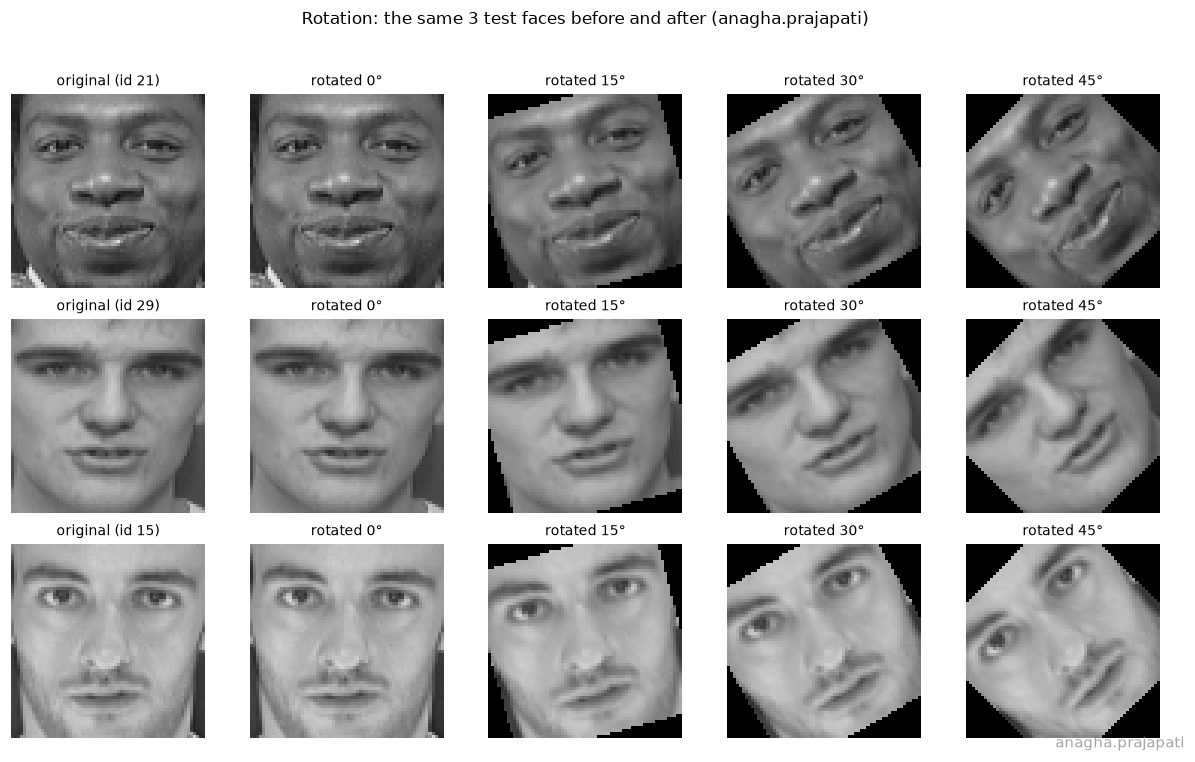

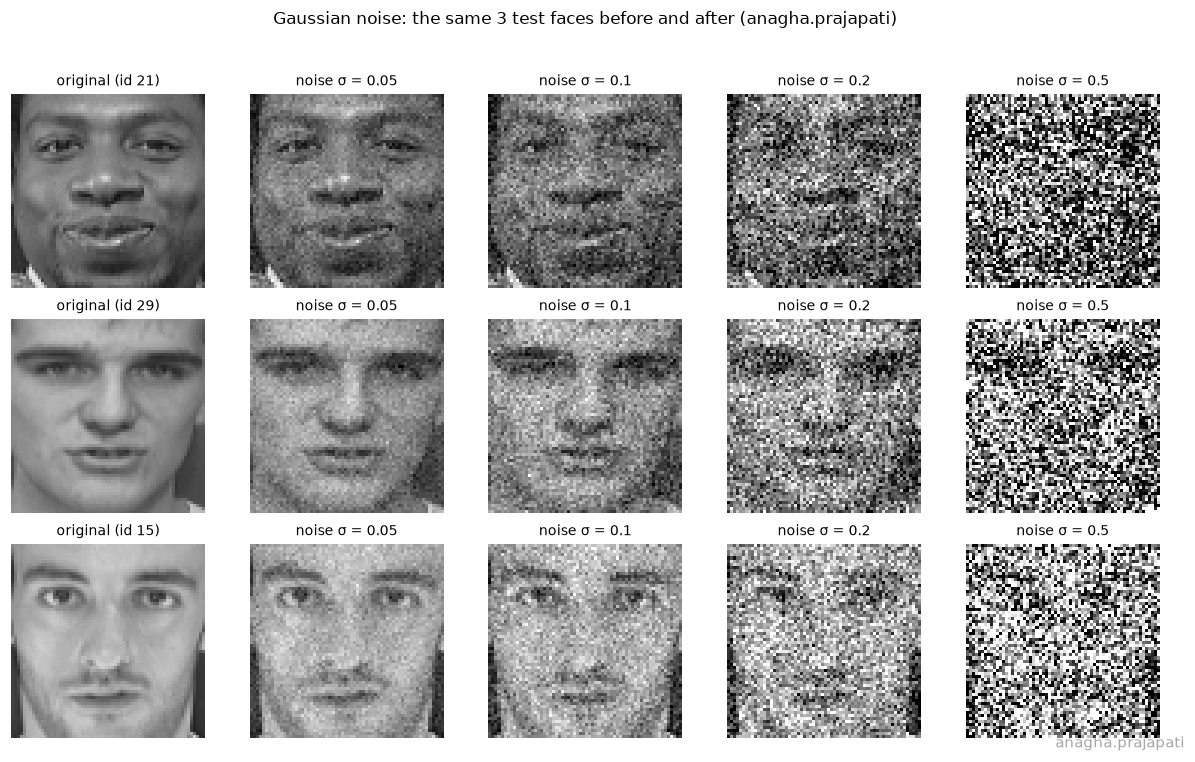

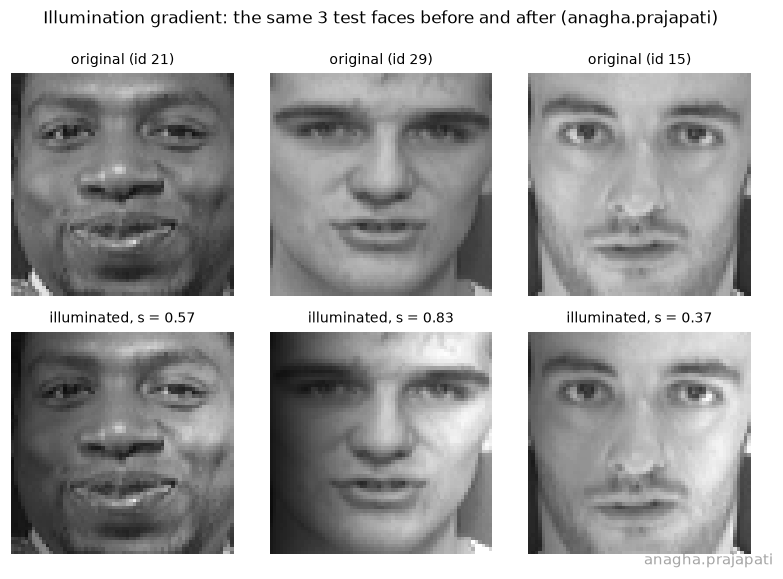

In [6]:
SHOW = rng.choice(len(img_test), size=3, replace=False)   # the same 3 test faces are shown in every figure
print("test faces shown in all before/after figures: test indices", SHOW.tolist(), "| identities", y_test[SHOW].tolist())

fig, axes = plt.subplots(3, 5, figsize=(11, 6.9))
for r, i in enumerate(SHOW):
    show_face(axes[r, 0], img_test[i], f"original (id {y_test[i]})")
    for c, a in enumerate(ANGLES):
        show_face(axes[r, c + 1], img_rot[a][i], f"rotated {a}°")
fig.suptitle(f"Rotation: the same 3 test faces before and after ({USERNAME})", fontsize=11)
finish(fig, "1_rotation_examples", hspace=0.16)

fig, axes = plt.subplots(3, 5, figsize=(11, 6.9))
for r, i in enumerate(SHOW):
    show_face(axes[r, 0], img_test[i], f"original (id {y_test[i]})")
    for c, s in enumerate(SIGMAS):
        show_face(axes[r, c + 1], img_noise[s][i], f"noise σ = {s}")
fig.suptitle(f"Gaussian noise: the same 3 test faces before and after ({USERNAME})", fontsize=11)
finish(fig, "1_noise_examples", hspace=0.16)

fig, axes = plt.subplots(2, 3, figsize=(7.2, 5.2))
for c, i in enumerate(SHOW):
    show_face(axes[0, c], img_test[i], f"original (id {y_test[i]})")
    show_face(axes[1, c], img_test_illum[i], f"illuminated, s = {s_test[i]:.2f}")
fig.suptitle(f"Illumination gradient: the same 3 test faces before and after ({USERNAME})", fontsize=11)
finish(fig, "1_illumination_examples", hspace=0.16)

---
# 2.2 PCA from Scratch

Let $X$ be the $N \times D$ training matrix ($N = 320$ faces, $D = 4096$ pixels), $\mu$ the training mean face and $X_c = X - \mu$.

**`"direct"`** eigendecomposes the $D \times D$ covariance matrix
$$C = \frac{X_c^\top X_c}{N-1}, \qquad C\,u_i = \lambda_i u_i .$$

**`"gram_trick"`** eigendecomposes the much smaller $N \times N$ matrix
$$L = \frac{X_c X_c^\top}{N-1}, \qquad L\,v_i = \lambda_i v_i .$$
Multiplying $L v_i = \lambda_i v_i$ from the left by $X_c^\top$ gives $\frac{X_c^\top X_c}{N-1}\,(X_c^\top v_i) = \lambda_i\,(X_c^\top v_i)$, that is $C\,(X_c^\top v_i) = \lambda_i\,(X_c^\top v_i)$. So $X_c^\top v_i$ is an eigenvector of $C$ **with the same eigenvalue**. Its length is $\lVert X_c^\top v_i\rVert = \sqrt{(N-1)\lambda_i}$, so the unit-length eigenvector is
$$u_i = \frac{X_c^\top v_i}{\sqrt{(N-1)\,\lambda_i}} .$$

Because the data are centred, $X_c$ has rank at most $N - 1 = 319$, so $C$ has at most 319 non-zero eigenvalues; the other $D - 319$ are zero. Both methods therefore describe the same components.

**Implementation details.**
* Both matrices are symmetric, so `np.linalg.eigh` is used. It returns eigenvalues in ascending order; we re-sort them in decreasing order.
* An eigenvalue counts as non-zero when it is larger than $10^{-10}\,\lambda_{\max}$. This removes the eigenvalues that are zero in exact arithmetic but come out as tiny positive or negative numbers numerically. `k=None` keeps all components with non-zero eigenvalue.
* `explained_variance_ratio_` divides each eigenvalue by the **total** variance $\operatorname{tr}(C) = \frac{1}{N-1}\sum X_c^2$, so the ratios do not depend on how many components are kept.
* The sign of an eigenvector is arbitrary. For reproducible pictures, each component is flipped so that its largest-magnitude entry is positive.
* `transform(X, k)` returns $Z = (X - \mu)\,U_k^\top$ and `inverse_transform(Z)` returns $\hat X = Z\,U_k + \mu$, where $U_k$ holds the first $k$ components as rows and $k$ is read from the number of columns of $Z$.

In [7]:
class PCAFromScratch:
    """Principal Component Analysis with NumPy only.

    method="direct"     : eigendecomposition of the D x D covariance matrix  C = Xc^T Xc / (N-1)
    method="gram_trick" : eigendecomposition of the N x N Gram matrix        L = Xc Xc^T / (N-1),
                          then  u_i = Xc^T v_i / sqrt((N-1) * lambda_i)
    Attributes after fit: mean_ (D,), components_ (k, D) sorted by decreasing eigenvalue,
                          eigenvalues_ (k,), explained_variance_ratio_ (k,), total_variance_.
    """

    def __init__(self, method="direct"):
        if method not in ("direct", "gram_trick"):
            raise ValueError('method must be "direct" or "gram_trick"')
        self.method = method

    def fit(self, X, k=None):
        X = np.asarray(X, dtype=np.float64)
        N, D = X.shape
        self.mean_ = X.mean(axis=0)                       # mean face (training data only)
        Xc = X - self.mean_
        self.total_variance_ = float((Xc ** 2).sum() / (N - 1))   # trace of the covariance matrix

        if self.method == "direct":
            C = Xc.T @ Xc / (N - 1)                       # D x D
            eigvals, eigvecs = np.linalg.eigh(C)          # ascending order
            order = np.argsort(eigvals)[::-1]
            eigvals, U = eigvals[order], eigvecs[:, order]            # columns are eigenvectors of C
            keep = eigvals > 1e-10 * eigvals[0]           # non-zero eigenvalues only
            eigvals, U = eigvals[keep], U[:, keep]
        else:
            L = Xc @ Xc.T / (N - 1)                       # N x N
            eigvals, V = np.linalg.eigh(L)
            order = np.argsort(eigvals)[::-1]
            eigvals, V = eigvals[order], V[:, order]
            keep = eigvals > 1e-10 * eigvals[0]
            eigvals, V = eigvals[keep], V[:, keep]
            U = Xc.T @ V / np.sqrt((N - 1) * eigvals)     # unit-length eigenvectors of C (columns)

        if k is not None:
            eigvals, U = eigvals[:k], U[:, :k]
        components = U.T                                  # (k, D), one component per row
        # fix the arbitrary sign: largest-magnitude entry of every component is positive
        signs = np.sign(components[np.arange(len(components)), np.abs(components).argmax(axis=1)])
        self.components_ = components * signs[:, None]
        self.eigenvalues_ = eigvals
        self.explained_variance_ratio_ = eigvals / self.total_variance_
        self.n_components_ = len(eigvals)
        return self

    def transform(self, X, k=None):
        """X: (M, D) -> Z: (M, k) coordinates on the first k components."""
        k = self.n_components_ if k is None else k
        if k > self.n_components_:
            raise ValueError(f"only {self.n_components_} components are available")
        return (np.asarray(X, dtype=np.float64) - self.mean_) @ self.components_[:k].T

    def inverse_transform(self, Z):
        """Z: (M, k) -> X_hat: (M, D) reconstruction from the first k components."""
        Z = np.asarray(Z, dtype=np.float64)
        return Z @ self.components_[: Z.shape[1]] + self.mean_

## 2.2.1 Fitting time of the two methods

Each method is fitted several times on the 320 × 4096 training matrix (3 runs for `direct`, 10 for `gram_trick`), keeping all components with non-zero eigenvalue.

In [8]:
def time_fit(method, repeats):
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        model = PCAFromScratch(method).fit(X_train)
        times.append(time.perf_counter() - t0)
    return model, np.array(times)


pca_direct, t_direct = time_fit("direct", 3)
pca_gram, t_gram = time_fit("gram_trick", 10)

timing = pd.DataFrame({
    "matrix eigendecomposed": [f"C: {D} x {D}", f"L: {N_TRAIN} x {N_TRAIN}"],
    "matrix entries": [D * D, N_TRAIN * N_TRAIN],
    "fit time, mean (s)": [t_direct.mean(), t_gram.mean()],
    "fit time, min (s)": [t_direct.min(), t_gram.min()],
    "runs": [len(t_direct), len(t_gram)],
    "components kept (non-zero eigenvalue)": [pca_direct.n_components_, pca_gram.n_components_],
}, index=["direct", "gram_trick"])
display(fmt(timing).format("{:.4f}", subset=["fit time, mean (s)", "fit time, min (s)"])
        .format("{:,}", subset=["matrix entries"]))
print(f"speed-up of gram_trick over direct: {t_direct.mean() / t_gram.mean():.0f}x (mean times)")
print(f"ratio of matrix sizes D/N = {D / N_TRAIN:.1f};  (D/N)^2 = {(D / N_TRAIN) ** 2:.0f};  (D/N)^3 = {(D / N_TRAIN) ** 3:.0f}")

,matrix eigendecomposed,matrix entries,"fit time, mean (s)","fit time, min (s)",runs,components kept (non-zero eigenvalue)
direct,C: 4096 x 4096,"16,777,216",19.7776,18.9029,3,319
gram_trick,L: 320 x 320,"102,400",0.2147,0.1997,10,319


speed-up of gram_trick over direct: 92x (mean times)
ratio of matrix sizes D/N = 12.8;  (D/N)^2 = 164;  (D/N)^3 = 2097


**Why the Gram trick is so much faster.** Both methods return the same 319 components, but they decompose matrices of very different size.

| | `direct` | `gram_trick` |
|---|---|---|
| matrix | $C$: 4096 × 4096 (16.8 million entries, 134 MB) | $L$: 320 × 320 (102,400 entries, 0.8 MB) |
| building the matrix | $X_c^\top X_c$: about $N D^2 \approx 5.4\times10^{9}$ multiplications | $X_c X_c^\top$: about $N^2 D \approx 4.2\times10^{8}$ |
| eigendecomposition, $O(n^3)$ | $D^3 \approx 6.9\times10^{10}$ | $N^3 \approx 3.3\times10^{7}$ |
| recovering $u_i = X_c^\top v_i/\sqrt{(N-1)\lambda_i}$ | not needed | about $N^2 D \approx 4.2\times10^{8}$ |

* The eigendecomposition costs $O(n^3)$ for an $n \times n$ matrix. The matrix side shrinks by $D/N = 12.8$, so this step alone needs about $12.8^3 \approx 2{,}100$ times fewer operations.
* In the measurement, `direct` takes roughly 20 seconds and `gram_trick` a few tenths of a second, a speed-up of roughly **80 to 90 times** (exact values in the table above; they vary a little from run to run). The measured speed-up is smaller than 2,100 because, once the eigendecomposition is this cheap, the Gram method's time is dominated by the two matrix products of size $N^2 D$, which the trick does not remove.
* The direct method also wastes work: it computes all 4,096 eigenpairs, although only 319 eigenvalues can be non-zero when 320 centred faces are used. The Gram method computes exactly the useful ones.
* In general the Gram trick pays off whenever $N \ll D$, which is the normal situation for images. If there were more faces than pixels ($N > D$), the direct method would be the cheaper one.

## 2.2.2 Do the two methods agree? (top 50 components)

In [9]:
TOP = 50
eig_diff = np.abs(pca_direct.eigenvalues_[:TOP] - pca_gram.eigenvalues_[:TOP])


def abs_correlation(a, b):
    """|Pearson correlation| between two vectors (sign-independent)."""
    a, b = a - a.mean(), b - b.mean()
    return abs(float(a @ b / np.sqrt((a @ a) * (b @ b))))


corr = np.array([abs_correlation(pca_direct.components_[i], pca_gram.components_[i]) for i in range(TOP)])
cosine = np.array([abs(float(pca_direct.components_[i] @ pca_gram.components_[i])) for i in range(TOP)])

print(f"largest absolute eigenvalue difference over the top {TOP}: {eig_diff.max():.3e} "
      f"(at component {eig_diff.argmax() + 1}; eigenvalues range from {pca_gram.eigenvalues_[0]:.4f} down to {pca_gram.eigenvalues_[TOP - 1]:.4f})")
print(f"largest relative eigenvalue difference: {(eig_diff / pca_gram.eigenvalues_[:TOP]).max():.3e}")
print(f"absolute correlation of corresponding components: min {corr.min():.12f}, mean {corr.mean():.12f}, max {corr.max():.12f}")
print(f"absolute cosine similarity                       : min {cosine.min():.12f}")
print(f"unit length check (gram_trick, top {TOP}): max | ||u_i|| - 1 | = "
      f"{np.abs(np.linalg.norm(pca_gram.components_[:TOP], axis=1) - 1).max():.2e}")
G = pca_gram.components_[:TOP] @ pca_gram.components_[:TOP].T
print(f"orthogonality check (gram_trick, top {TOP}): max |u_i . u_j| for i != j = {np.abs(G - np.eye(TOP)).max():.2e}")

pair_table = pd.DataFrame({"component": np.arange(1, TOP + 1), "eigenvalue (direct)": pca_direct.eigenvalues_[:TOP],
                           "eigenvalue (gram_trick)": pca_gram.eigenvalues_[:TOP], "|difference|": eig_diff,
                           "|correlation|": corr}).set_index("component")
with pd.option_context("display.max_rows", 60):
    display(fmt(pair_table).format("{:.6f}", subset=["eigenvalue (direct)", "eigenvalue (gram_trick)"])
            .format("{:.2e}", subset=["|difference|"]).format("{:.10f}", subset=["|correlation|"]))

pca = pca_gram          # the model used from here on (fitted on the clean training set, all 319 components)
Z_check = pca.transform(X_train)
print(f"\nmodel used from here on: gram_trick, {pca.n_components_} components")
print(f"sanity: with all components the training faces are reconstructed exactly, max error = "
      f"{np.abs(pca.inverse_transform(Z_check) - X_train).max():.2e}")
print(f"sanity: variance of the projections equals the eigenvalues, max relative error = "
      f"{np.abs(Z_check.var(axis=0, ddof=1) / pca.eigenvalues_ - 1).max():.2e}")

largest absolute eigenvalue difference over the top 50: 1.066e-14 (at component 2; eigenvalues range from 18.2388 down to 0.1644)
largest relative eigenvalue difference: 3.747e-15
absolute correlation of corresponding components: min 1.000000000000, mean 1.000000000000, max 1.000000000000
absolute cosine similarity                       : min 1.000000000000
unit length check (gram_trick, top 50): max | ||u_i|| - 1 | = 2.22e-15
orthogonality check (gram_trick, top 50): max |u_i . u_j| for i != j = 4.00e-15


,eigenvalue (direct),eigenvalue (gram_trick),|difference|,|correlation|
component,,,,
1,18.238828,18.238828,7.11e-15,1.0000000000
2,10.828516,10.828516,1.07e-14,1.0000000000
3,6.331275,6.331275,8.88e-16,1.0000000000
4,4.022341,4.022341,0.00e+00,1.0000000000
5,2.963904,2.963904,3.11e-15,1.0000000000
6,2.560217,2.560217,4.88e-15,1.0000000000
7,1.938346,1.938346,6.66e-16,1.0000000000
8,1.595012,1.595012,1.33e-15,1.0000000000
9,1.581329,1.581329,5.33e-15,1.0000000000



model used from here on: gram_trick, 319 components
sanity: with all components the training faces are reconstructed exactly, max error = 4.36e-14
sanity: variance of the projections equals the eigenvalues, max relative error = 9.30e-14


**Result.** For the top 50 components the two methods agree to machine precision.

* **Eigenvalues.** The largest absolute difference is about $1.1\times10^{-14}$, for eigenvalues between 18.24 and 0.16. The largest relative difference is about $4\times10^{-15}$, which is the rounding level of 64-bit floating point.
* **Components.** The absolute correlation between each pair of corresponding components is 1.000000000000 for all 50 pairs (the minimum equals 1 to 12 decimals). The absolute value is used because an eigenvector's sign is arbitrary: $u$ and $-u$ describe the same axis.
* **Extra checks.** The Gram-trick components have unit length and are mutually orthogonal to within $10^{-14}$. With all 319 components the training faces are reconstructed exactly, and the variance of the projected training data along each component equals its eigenvalue.

**Method used from here on: `gram_trick`.** It gives the same eigenvalues and components as the direct method, is roughly 80 to 90 times faster, and needs far less memory. The model `pca` is fitted once on the clean training set with all 319 components; `transform(X, k)` then selects the first $k$.

## 2.2.3 Mean face and the top 15 eigenfaces

The mean face is shown on the pixel scale [0, 1]. A component has positive and negative entries, so each eigenface is shown on its own symmetric grey scale: mid-grey is 0, white is positive and black is negative.

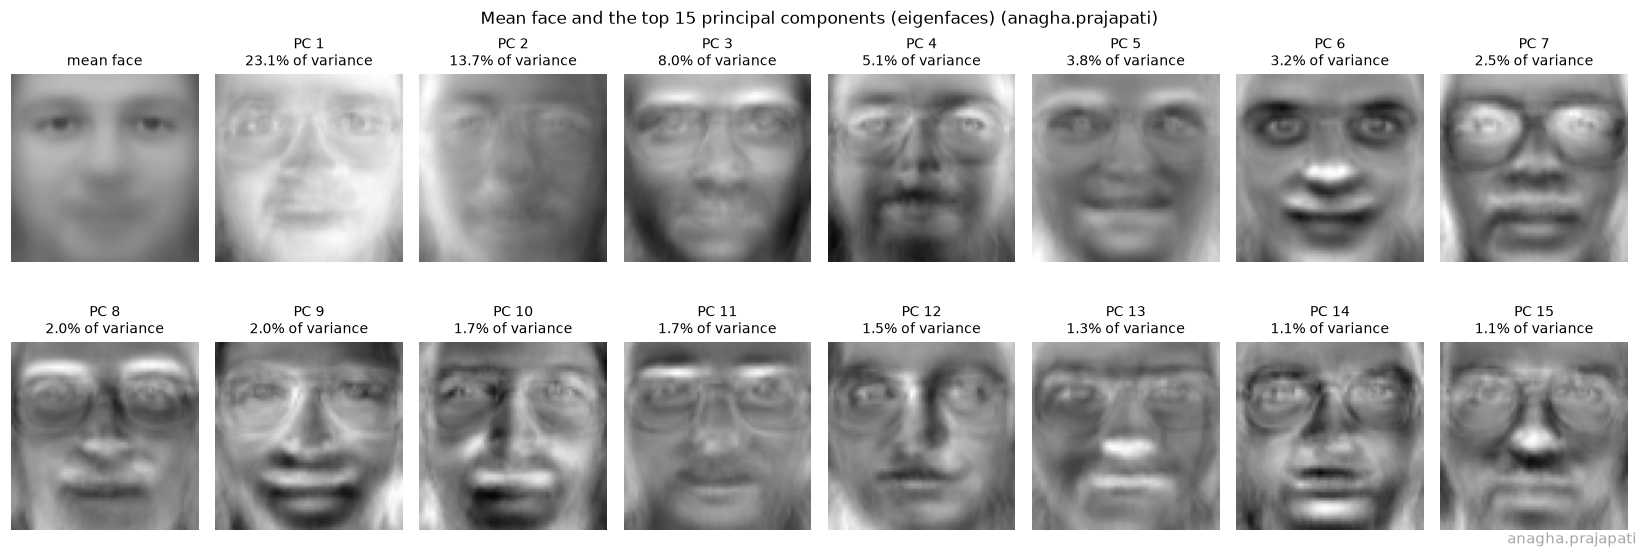

In [10]:
fig, axes = plt.subplots(2, 8, figsize=(15, 5.0))
show_face(axes[0, 0], pca.mean_, "mean face")
for i in range(15):
    ax = axes.ravel()[i + 1]
    comp = pca.components_[i]
    lim = np.abs(comp).max()
    show_face(ax, comp, f"PC {i + 1}\n{100 * pca.explained_variance_ratio_[i]:.1f}% of variance", vmin=-lim, vmax=lim)
fig.suptitle(f"Mean face and the top 15 principal components (eigenfaces) ({USERNAME})", fontsize=11)
finish(fig, "2_mean_and_eigenfaces", hspace=0.38)

**What the eigenfaces show.**

* The **mean face** is a blurred, generic face: every person-specific detail has been averaged away.
* The **first components are smooth, large-scale patterns.** PC 1 (23.1% of the variance) is almost uniformly bright across the face: it mostly encodes overall brightness. PC 2 and PC 3 (13.7% and 8.0%) are broad light-and-shade patterns over the face, forehead, hair region and image border. These three components already hold 45% of the variance, and they describe lighting and coarse appearance more than identity.
* **Later components carry local facial structure**: spectacle frames (clearly visible in PC 4, 7, 8, 9 and 14), eyebrows and eye regions, the mouth and moustache area, and the nose highlight (PC 6, 13 and 15).
* Each component is a **whole-face (global) pattern**, not a single part: changing one coefficient changes pixels all over the image. This is a property of PCA, which only maximises variance and knows nothing about facial parts.

---
# 2.3 Compression and Reconstruction

## 2.3.1 How many numbers must be stored?

**Raw storage.** $N$ faces with $D$ pixels each need $N \cdot D$ values.

**Compressed storage.** To reconstruct $\hat x_n = \mu + \sum_{i=1}^{k} z_{ni}\,u_i$ for every face we must keep:

| item | stored | values |
|---|---|---|
| mean face $\mu$ | once | $D$ |
| the $k$ components $u_1,\dots,u_k$ | once | $k \cdot D$ |
| the $k$ coefficients of each face | per face | $N \cdot k$ |

$$\text{compressed storage} = N k + k D + D = k\,(N + D) + D, \qquad
\text{compression ratio} = \frac{N D}{k\,(N + D) + D}.$$

With $N = 320$ and $D = 4096$ the raw storage is 1,310,720 values. The shared part (mean and components) costs $(k+1)\cdot 4096$ values and dominates: each extra component costs 4,096 shared values but only 320 coefficient values. Compression only pays off (ratio > 1) while $k(N+D) + D < ND$, that is for $k \le 295$.

In [11]:
def compression_ratio(N, D, k):
    """Raw storage (N * D) divided by compressed storage."""
    compressed = N * k + k * D + D      # coefficients + components + mean face
    return (N * D) / compressed


ratio_table = pd.DataFrame([{"k": k, "raw values (N*D)": N_STORE * D_STORE,
                             "compressed values": N_STORE * k + k * D_STORE + D_STORE,
                             "compression ratio": compression_ratio(N_STORE, D_STORE, k)}
                            for k in [1, 5, 10, 20, 50, 100, 200, 295, 296]]).set_index("k")
display(fmt(ratio_table).format("{:.2f}", subset=["compression ratio"])
        .format("{:,}", subset=["raw values (N*D)", "compressed values"]))

,raw values (N*D),compressed values,compression ratio
k,,,
1,"1,310,720","8,512",153.98
5,"1,310,720","26,176",50.07
10,"1,310,720","48,256",27.16
20,"1,310,720","92,416",14.18
50,"1,310,720","224,896",5.83
100,"1,310,720","445,696",2.94
200,"1,310,720","887,296",1.48
295,"1,310,720","1,306,816",1.00
296,"1,310,720","1,311,232",1.00


## 2.3.2 Reconstructions at k = 10, 50, 100

The same 3 clean test faces as before are projected on the first $k$ components and reconstructed. The number under each reconstruction is that face's own MSE.

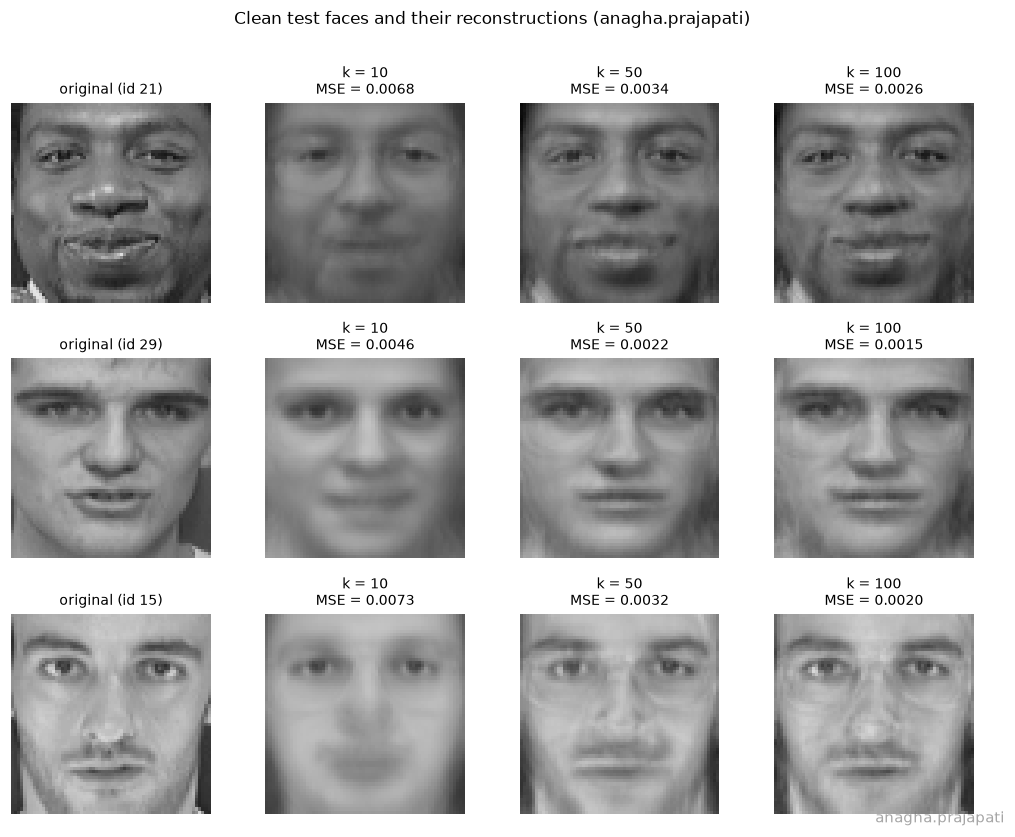

In [12]:
def reconstruct(model, X, k):
    """Project X on the first k components of `model` and map back to pixel space."""
    return model.inverse_transform(model.transform(X, k))


K_SHOW = [10, 50, 100]
fig, axes = plt.subplots(3, 4, figsize=(9.4, 7.6))
for r, i in enumerate(SHOW):
    show_face(axes[r, 0], X_test[i], f"original (id {y_test[i]})")
    for c, k in enumerate(K_SHOW):
        rec = reconstruct(pca, X_test[i:i + 1], k)[0]
        show_face(axes[r, c + 1], np.clip(rec, 0, 1), f"k = {k}\nMSE = {np.mean((rec - X_test[i]) ** 2):.4f}")
fig.suptitle(f"Clean test faces and their reconstructions ({USERNAME})", fontsize=11)
finish(fig, "3_reconstructions", hspace=0.28)

**Which details disappear first as k decreases, and why.**

* **k = 100.** The faces are clearly recognisable. What is missing is fine texture: skin detail, the sharpness of the eyes and lips, and the bright highlight on the nose of the first face.
* **k = 50.** The identity is still visible, but edges are softer. The exact shape of the mouth and the teeth of the first face are smeared, and the shirt collar at the bottom of the image has gone. The third face shows faint **"ghost" spectacles** although the person wears none: several leading components contain spectacle frames (see 2.2.3), and with only 50 components there are not enough other components to cancel them completely.
* **k = 10.** All three reconstructions look like a blurred generic face. Only the overall brightness, the head outline and the rough position of eyes, nose and mouth survive. The three people are hard to tell apart.

**So the order of loss is:** first the fine, high-frequency, person-specific details (texture, highlights, sharp edges of eyes and mouth, small accessories and background corners), then medium-scale shape (exact form of mouth, nose and eyebrows), and last the coarse, low-frequency structure (brightness, lighting, head shape).

**Why.** PCA orders its components by the variance they explain over the training faces. Large smooth changes such as brightness, lighting direction and head shape affect thousands of pixels at once and differ a lot from image to image, so they have large variance and occupy the first components. A fine detail affects few pixels, and it differs from face to face in position and shape, so its variance is small and spread over many low-eigenvalue components. Truncating to k components keeps the high-variance directions and discards the rest, so fine detail goes first. This is also why PCA is the *optimal* linear compression in the mean-squared-error sense: the discarded directions are exactly the ones that cost the least squared error on average.

## 2.3.3 Reconstruction MSE, compression ratio and explained variance

$$\text{MSE}(A, B) = \frac{1}{M D}\sum_{m=1}^{M}\sum_{d=1}^{D} (A_{md} - B_{md})^2 ,$$
the mean squared pixel difference over all images and all pixels. Reconstructions are **not** clipped before the MSE is computed.

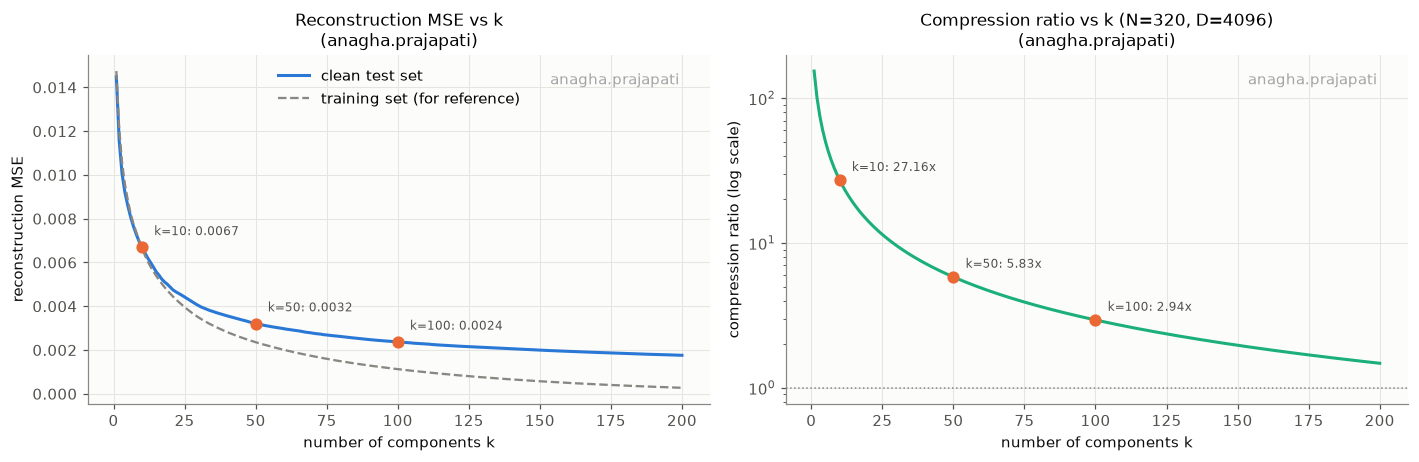

,clean test MSE,train MSE,compression ratio,values stored
k,,,,
10,0.00669,0.00666,27.16,"48,256"
50,0.00321,0.00236,5.83,"224,896"
100,0.00237,0.00113,2.94,"445,696"


MSE of using the mean face alone (k = 0): 0.01963


In [13]:
def reconstruction_mse(A, B):
    """Mean squared pixel difference over all images and pixels."""
    A, B = np.asarray(A, dtype=np.float64), np.asarray(B, dtype=np.float64)
    return float(np.mean((A - B) ** 2))


K_RANGE = np.arange(1, 201)
mse_test_curve = np.array([reconstruction_mse(X_test, reconstruct(pca, X_test, k)) for k in K_RANGE])
mse_train_curve = np.array([reconstruction_mse(X_train, reconstruct(pca, X_train, k)) for k in K_RANGE])
ratio_curve = np.array([compression_ratio(N_STORE, D_STORE, k) for k in K_RANGE])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
ax.plot(K_RANGE, mse_test_curve, color=BLUE, label="clean test set")
ax.plot(K_RANGE, mse_train_curve, color=MUTED, lw=1.5, ls="--", label="training set (for reference)")
for k in K_SHOW:
    ax.plot(k, mse_test_curve[k - 1], "o", color=ORANGE)
    ax.annotate(f"k={k}: {mse_test_curve[k - 1]:.4f}", (k, mse_test_curve[k - 1]), textcoords="offset points",
                xytext=(8, 8), fontsize=8, color=INK2)
ax.set_xlabel("number of components k")
ax.set_ylabel("reconstruction MSE")
ax.legend(loc="upper center")
titled(ax, "Reconstruction MSE vs k")
ax = axes[1]
ax.plot(K_RANGE, ratio_curve, color=AQUA)
ax.axhline(1, color=MUTED, lw=1, ls=":")
for k in K_SHOW:
    ax.plot(k, ratio_curve[k - 1], "o", color=ORANGE)
    ax.annotate(f"k={k}: {ratio_curve[k - 1]:.2f}x", (k, ratio_curve[k - 1]), textcoords="offset points",
                xytext=(8, 6), fontsize=8, color=INK2)
ax.set_yscale("log")
ax.set_xlabel("number of components k")
ax.set_ylabel("compression ratio (log scale)")
titled(ax, f"Compression ratio vs k (N={N_STORE}, D={D_STORE})")
finish(fig, "3_mse_and_ratio_vs_k")

mse_ratio_table = pd.DataFrame({"clean test MSE": [mse_test_curve[k - 1] for k in K_SHOW],
                                "train MSE": [mse_train_curve[k - 1] for k in K_SHOW],
                                "compression ratio": [ratio_curve[k - 1] for k in K_SHOW],
                                "values stored": [N_STORE * k + k * D_STORE + D_STORE for k in K_SHOW]},
                               index=pd.Index(K_SHOW, name="k"))
display(fmt(mse_ratio_table).format("{:.5f}", subset=["clean test MSE", "train MSE"])
        .format("{:.2f}", subset=["compression ratio"]).format("{:,}", subset=["values stored"]))
print(f"MSE of using the mean face alone (k = 0): {reconstruction_mse(X_test, np.tile(pca.mean_, (len(X_test), 1))):.5f}")

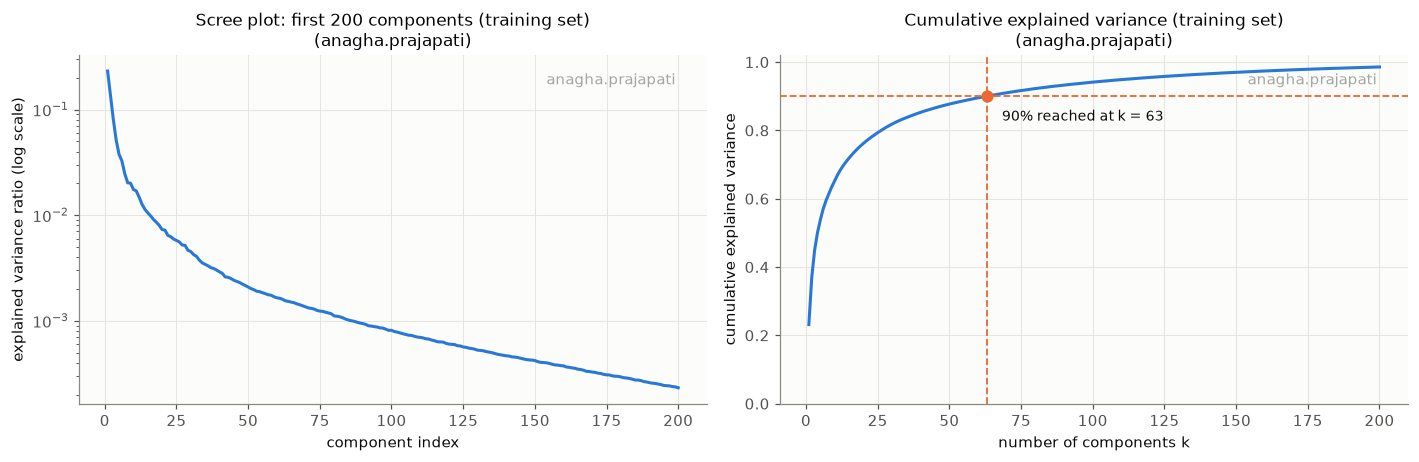

explained variance of the first components: PC1 23.1%, PC2 13.7%, PC3 8.0%, PC4 5.1%, PC5 3.8%
cumulative explained variance at k = 10, 20, 50, 100, 200: 65.3%, 76.2%, 87.7%, 94.1%, 98.6%
smallest k reaching 90% of the training variance: k = 63  (cumulative 90.01%; k = 62 gives 89.86%)
for reference: 95% at k = 112, 99% at k = 222


In [14]:
evr = pca.explained_variance_ratio_           # computed from the TRAINING set only
cum = np.cumsum(evr)
k90 = int(np.argmax(cum >= 0.90) + 1)
k95 = int(np.argmax(cum >= 0.95) + 1)
k99 = int(np.argmax(cum >= 0.99) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
ax.plot(K_RANGE, evr[:200], color=BLUE)
ax.set_yscale("log")
ax.set_xlabel("component index")
ax.set_ylabel("explained variance ratio (log scale)")
titled(ax, "Scree plot: first 200 components (training set)")
ax = axes[1]
ax.plot(K_RANGE, cum[:200], color=BLUE)
ax.axhline(0.90, color=ORANGE, lw=1.2, ls="--")
ax.axvline(k90, color=ORANGE, lw=1.2, ls="--")
ax.plot(k90, cum[k90 - 1], "o", color=ORANGE)
ax.annotate(f"90% reached at k = {k90}", (k90, cum[k90 - 1]), textcoords="offset points", xytext=(10, -16),
            fontsize=9, color=INK)
ax.set_xlabel("number of components k")
ax.set_ylabel("cumulative explained variance")
ax.set_ylim(0, 1.02)
titled(ax, "Cumulative explained variance (training set)")
finish(fig, "3_scree_and_cumulative")

print(f"explained variance of the first components: " + ", ".join(f"PC{i + 1} {100 * evr[i]:.1f}%" for i in range(5)))
print(f"cumulative explained variance at k = 10, 20, 50, 100, 200: "
      + ", ".join(f"{100 * cum[k - 1]:.1f}%" for k in [10, 20, 50, 100, 200]))
print(f"smallest k reaching 90% of the training variance: k = {k90}  (cumulative {100 * cum[k90 - 1]:.2f}%; "
      f"k = {k90 - 1} gives {100 * cum[k90 - 2]:.2f}%)")
print(f"for reference: 95% at k = {k95}, 99% at k = {k99}")

**Results.**

| k | clean test MSE | compression ratio | cumulative training variance |
|---|---|---|---|
| 10 | 0.00669 | 27.16 | 65.3% |
| 50 | 0.00321 | 5.83 | 87.7% |
| 100 | 0.00237 | 2.94 | 94.1% |

The smallest k that reaches **90% of the training variance is k = 63** (90.01%; k = 62 gives 89.86%).

**What the MSE curve and the scree plot imply for choosing k.**

* **Strongly diminishing returns.** The scree plot falls very steeply: PC 1 alone explains 23.1% and the first 10 components 65.3%, while components beyond 100 each explain less than 0.1%. The MSE curve mirrors this. Using only the mean face gives an MSE of 0.0196; 10 components cut it to 0.0067 (by two thirds). Going from 10 to 50 halves it again (0.0067 → 0.0032). Going from 50 to 100 gains only another 26% (0.0032 → 0.0024).
* **Storage grows linearly while quality saturates.** Every additional component costs the same 4,416 values (4,096 for the component and 320 coefficients), so the compression ratio falls roughly as 1/k: 27.2 at k = 10, 5.8 at k = 50, 2.9 at k = 100. Each further component buys less and less accuracy for the same storage.
* **The elbow is at about k = 20 to 50.** Below about 20 the MSE is still falling fast, so a few extra components are well spent. Above about 50 the curve is nearly flat, so more components are mostly wasted storage.
* **Train and test curves separate.** Up to k ≈ 10 the two curves coincide: the first components describe variation that is common to all faces. After that the training MSE keeps falling towards 0 (it is exactly 0 at k = 319), while the test MSE levels off near 0.002. Later components increasingly describe the particular 320 training images, not faces in general. The scree plot and cumulative variance are computed on the training set, so they **overstate** the benefit of large k for new faces. Only the test MSE shows the real, lasting error.
* **A variance threshold is a starting point, not the answer.** The 90% rule suggests k = 63, where the compression ratio is only 4.6. Whether that is the right trade-off depends on what the compressed faces are used for. For recognition the decisive quantity is accuracy, not MSE or variance; Sections 2.4 and 2.5 show that a much smaller k is enough.

## 2.3.4 Reconstruction of the transformed test sets at $k_T = 50$

The PCA is the one fitted on the **clean training set**; only the test images change.

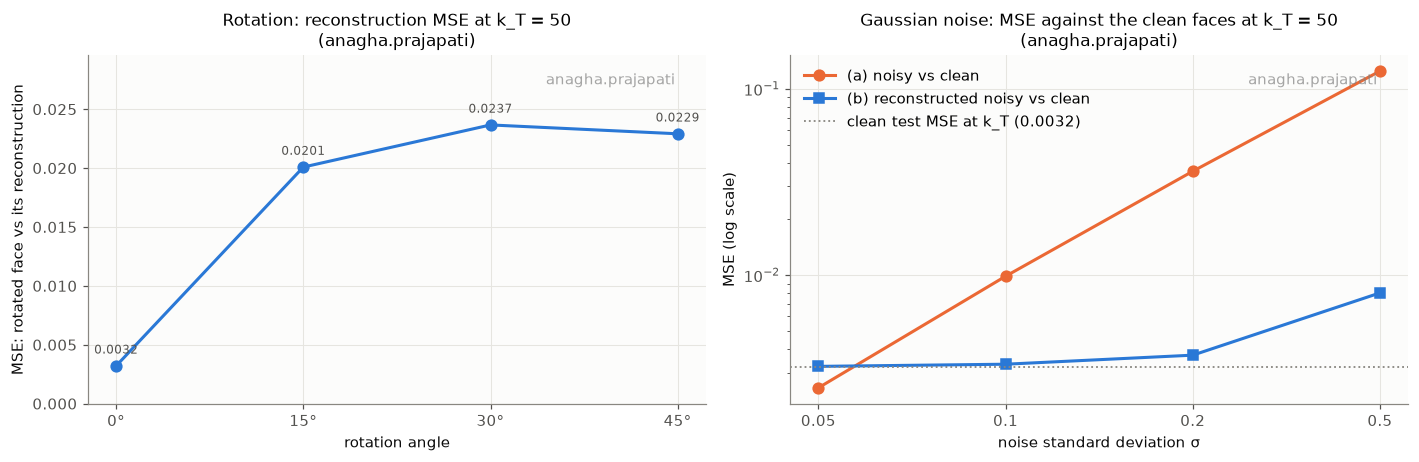

,MSE (rotated vs its reconstruction),ratio to clean test MSE
angle,,
0°,0.00321,1.00
15°,0.02008,6.26
30°,0.02366,7.38
45°,0.02291,7.14


,sigma^2 (before clipping),(a) MSE noisy vs clean,(b) MSE reconstructed noisy vs clean,(b) / (a),(b) - clean test MSE
sigma,,,,,
0.05,0.00250,0.00248,0.00324,1.303,0.00003
0.10,0.01000,0.00987,0.00333,0.337,0.00012
0.20,0.04000,0.03613,0.00372,0.103,0.00051
0.50,0.25000,0.12469,0.00803,0.064,0.00482


expected noise that survives projection on k_T components: sigma^2 * k_T / D = 0.000031, 0.000122, 0.000488, 0.003052


,MSE at k_T = 50
clean test set (face vs its reconstruction),0.00321
illuminated test set (illuminated face vs its reconstruction),0.00608


illumination MSE / clean MSE = 1.90


In [15]:
mse_clean_kT = reconstruction_mse(X_test, reconstruct(pca, X_test, K_T))

# rotation: rotated face vs. its own reconstruction
mse_rot = {a: reconstruction_mse(X_rot[a], reconstruct(pca, X_rot[a], K_T)) for a in ANGLES}
# noise: (a) noisy vs clean, (b) reconstruction of the noisy face vs clean; also the reconstruction of the clean face
mse_noisy_vs_clean = {s: reconstruction_mse(X_noise[s], X_test) for s in SIGMAS}
mse_recon_vs_clean = {s: reconstruction_mse(reconstruct(pca, X_noise[s], K_T), X_test) for s in SIGMAS}
# illumination: illuminated face vs. its own reconstruction
mse_illum = reconstruction_mse(X_test_illum, reconstruct(pca, X_test_illum, K_T))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
ax.plot(ANGLES, [mse_rot[a] for a in ANGLES], "o-", color=BLUE)
for a in ANGLES:
    ax.annotate(f"{mse_rot[a]:.4f}", (a, mse_rot[a]), textcoords="offset points", xytext=(0, 8), ha="center",
                fontsize=8, color=INK2)
ax.set_xticks(ANGLES, [f"{a}°" for a in ANGLES])
ax.set_xlabel("rotation angle")
ax.set_ylabel("MSE: rotated face vs its reconstruction")
ax.set_ylim(0, max(mse_rot.values()) * 1.25)
titled(ax, f"Rotation: reconstruction MSE at k_T = {K_T}")
ax = axes[1]
xs = np.arange(len(SIGMAS))
ax.plot(xs, [mse_noisy_vs_clean[s] for s in SIGMAS], "o-", color=ORANGE, label="(a) noisy vs clean")
ax.plot(xs, [mse_recon_vs_clean[s] for s in SIGMAS], "s-", color=BLUE, label="(b) reconstructed noisy vs clean")
ax.axhline(mse_clean_kT, color=MUTED, lw=1.2, ls=":", label=f"clean test MSE at k_T ({mse_clean_kT:.4f})")
ax.set_yscale("log")
ax.set_xticks(xs, [str(s) for s in SIGMAS])
ax.set_xlabel("noise standard deviation σ")
ax.set_ylabel("MSE (log scale)")
ax.legend(loc="upper left")
titled(ax, f"Gaussian noise: MSE against the clean faces at k_T = {K_T}")
finish(fig, "3_transformed_mse")

rot_table = pd.DataFrame({"MSE (rotated vs its reconstruction)": [mse_rot[a] for a in ANGLES],
                          "ratio to clean test MSE": [mse_rot[a] / mse_clean_kT for a in ANGLES]},
                         index=pd.Index([f"{a}°" for a in ANGLES], name="angle"))
display(fmt(rot_table).format("{:.5f}", subset=["MSE (rotated vs its reconstruction)"])
        .format("{:.2f}", subset=["ratio to clean test MSE"]))

noise_table = pd.DataFrame({
    "sigma^2 (before clipping)": [s ** 2 for s in SIGMAS],
    "(a) MSE noisy vs clean": [mse_noisy_vs_clean[s] for s in SIGMAS],
    "(b) MSE reconstructed noisy vs clean": [mse_recon_vs_clean[s] for s in SIGMAS],
    "(b) / (a)": [mse_recon_vs_clean[s] / mse_noisy_vs_clean[s] for s in SIGMAS],
    "(b) - clean test MSE": [mse_recon_vs_clean[s] - mse_clean_kT for s in SIGMAS],
}, index=pd.Index(SIGMAS, name="sigma"))
display(fmt(noise_table).format("{:.5f}", subset=["sigma^2 (before clipping)", "(a) MSE noisy vs clean",
                                                  "(b) MSE reconstructed noisy vs clean", "(b) - clean test MSE"])
        .format("{:.3f}", subset=["(b) / (a)"]))
print(f"expected noise that survives projection on k_T components: sigma^2 * k_T / D = "
      + ", ".join(f"{s ** 2 * K_T / D:.6f}" for s in SIGMAS))

illum_table = pd.DataFrame({"MSE at k_T = 50": [mse_clean_kT, mse_illum]},
                           index=["clean test set (face vs its reconstruction)",
                                  "illuminated test set (illuminated face vs its reconstruction)"])
display(fmt(illum_table).format("{:.5f}"))
print(f"illumination MSE / clean MSE = {mse_illum / mse_clean_kT:.2f}")

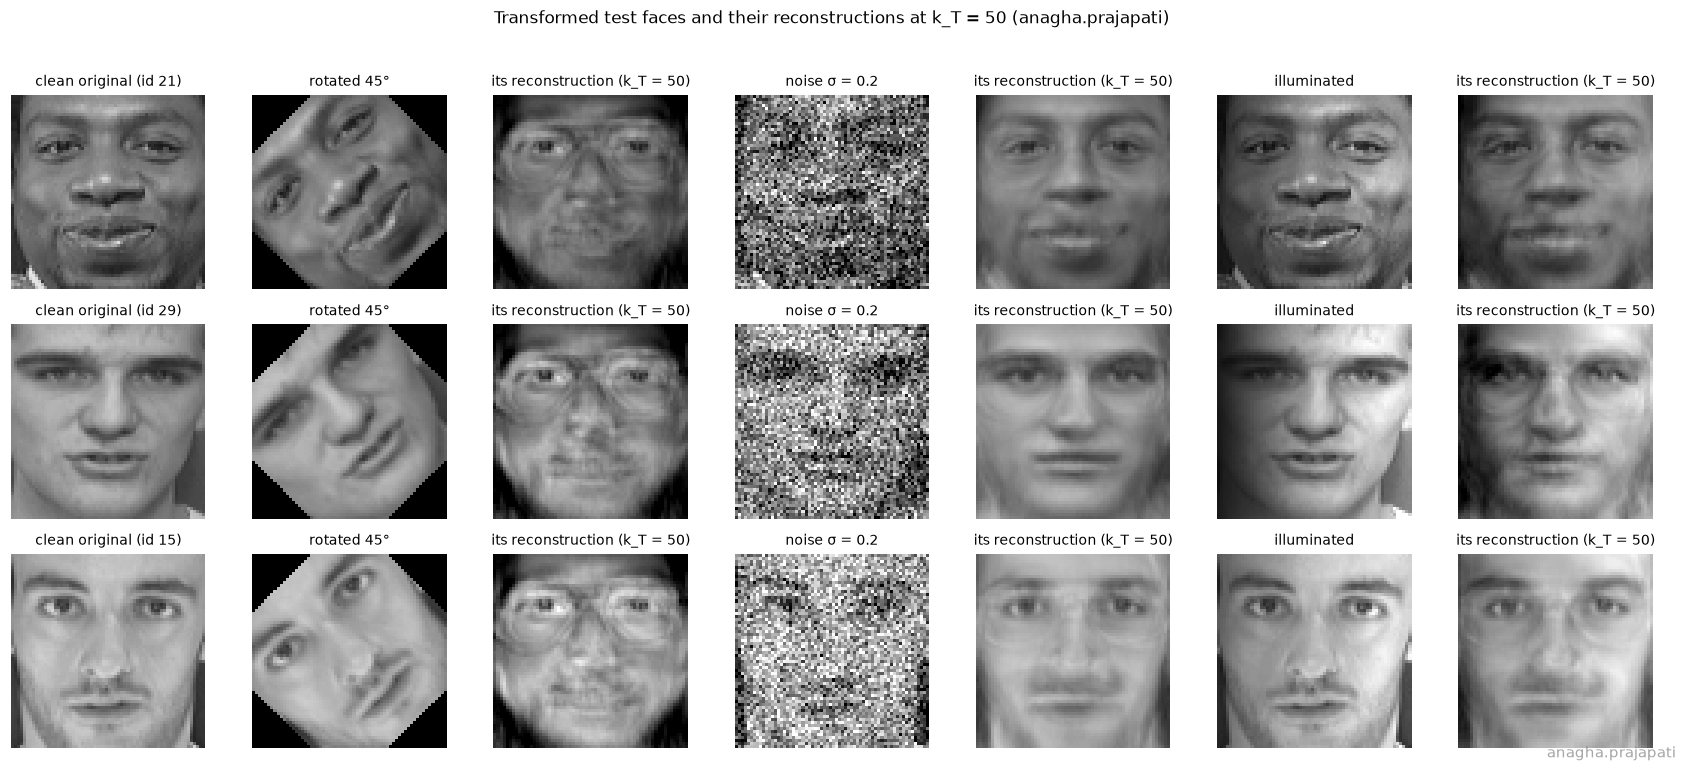

In [16]:
# what the reconstructions look like (same 3 test faces): strongest rotation, a strong noise level, illumination
fig, axes = plt.subplots(3, 7, figsize=(15.5, 7.0))
cases = [("clean", X_test), (f"rotated {ANGLES[-1]}°", X_rot[ANGLES[-1]]), ("noise σ = 0.2", X_noise[0.2])]
for r, i in enumerate(SHOW):
    show_face(axes[r, 0], X_test[i], f"clean original (id {y_test[i]})")
    col = 1
    for name, Xs in cases[1:] + [("illuminated", X_test_illum)]:
        show_face(axes[r, col], Xs[i], name)
        show_face(axes[r, col + 1], np.clip(reconstruct(pca, Xs[i:i + 1], K_T)[0], 0, 1), f"its reconstruction (k_T = {K_T})")
        col += 2
fig.suptitle(f"Transformed test faces and their reconstructions at k_T = {K_T} ({USERNAME})", fontsize=11)
finish(fig, "3_transformed_reconstructions", hspace=0.18)

**Rotation.** The reconstruction MSE jumps from 0.0032 (0°, identical to the clean test MSE) to 0.0201 at 15°, 0.0237 at 30° and 0.0229 at 45°, that is 6 to 7 times the clean value. Already the smallest rotation causes almost the whole increase; after that the curve is flat (the small drop from 30° to 45° is not meaningful). The eigenfaces were learned from upright, centred faces, so they can only build upright faces. A rotated face lies far outside the subspace they span, and the black corners (11% to 19% of the pixels) are a pattern no component contains. The figure above shows the result: the "reconstruction" of a face rotated by 45° is an upright, generic face with spectacle-like artefacts, unrelated to the input.

**Noise.**
* **(a) Noisy vs clean** is the noise power itself. For small σ it is almost exactly σ²: 0.0025 for σ = 0.05 and 0.0099 for σ = 0.1. For large σ it is smaller than σ² (0.036 instead of 0.04 for σ = 0.2; 0.125 instead of 0.25 for σ = 0.5), because clipping to [0, 1] cuts off the largest noise values.
* **(b) Reconstructed noisy vs clean** stays almost constant: 0.0032, 0.0033, 0.0037 and 0.0080. It is close to the clean test MSE (0.0032) at every level except the strongest.

**Why (a) and (b) differ.** Projecting on $k_T = 50$ components is a **denoising** step. Gaussian pixel noise is spread evenly over all $D = 4096$ directions of pixel space. The projection keeps only the 50 directions of the eigenface subspace, so only the fraction $k_T/D = 50/4096 \approx 1.2\%$ of the noise energy survives, while most of the face signal lies in that subspace and is kept. The reconstruction error against the clean face therefore has two parts,
$$\text{(b)} \approx \underbrace{\text{clean truncation error}}_{0.0032} + \underbrace{\sigma^2\,k_T/D}_{\text{noise that survives}} .$$
The predicted surviving noise is 0.00003, 0.00012 and 0.00049 for σ = 0.05, 0.1 and 0.2; the measured excess of (b) over the clean MSE is 0.00003, 0.00012 and 0.00051. The agreement is almost exact. For σ = 0.5 the excess (0.0048) is larger than predicted (0.0031): at this level a large share of the pixels is clipped, so the noise is no longer zero-mean and independent of the image. Clipping pulls dark pixels up and bright pixels down, which is a structured change that the components partly keep.

Two consequences follow. For σ ≥ 0.1 the reconstruction is much closer to the clean face than the noisy input is (3 to 16 times lower MSE). For σ = 0.05, however, (b) is slightly **larger** than (a) (0.0032 vs 0.0025): the truncation to 50 components always costs about 0.0032, which here is more than the noise it removes. PCA denoising only pays when the noise power σ² exceeds the truncation error, that is for σ above about 0.057.

**Illumination.** The MSE of an illuminated face against its own reconstruction is **0.00608, compared with 0.00321 for the clean test set (1.9 times higher)**. A left-to-right brightness gradient is a smooth, low-frequency pattern, and smooth lighting patterns are something the leading eigenfaces can partly represent. That is why the increase is far smaller than for rotation. It is not zero, because the clean training set contains no gradients of this strength, and because clipping the bright side to 1 creates flat saturated areas that the components cannot reproduce.

---
# 2.4 Face Recognition

**Classifier: 1-nearest-neighbour (`KNeighborsClassifier(n_neighbors=1)`) with the Euclidean distance.** Reasons:

* **It fits the data.** There are 40 classes with only 8 training images each. A nearest-neighbour rule needs no training of its own and no assumption about class shape, and it is the classical recognition rule of the eigenface method: "which enrolled face is closest?". This is also what a door lock does: it compares the new face with the stored templates.
* **k = 1 neighbour.** With 8 images per identity, a vote over several neighbours would quickly include other people, so a single neighbour is the natural choice. It also leaves **no hyperparameter to tune**, which matters because there is no validation set and the test set must not be used for tuning.
* **Euclidean distance matches PCA.** PCA components are orthonormal, so the Euclidean distance between two feature vectors equals the Euclidean distance between the two reconstructions in pixel space. PCA with k components is the linear projection that preserves squared Euclidean distances best on the training data, so the classifier and the representation use the same geometry. On raw pixels the same metric gives a directly comparable baseline.
* `algorithm="brute"` makes the search exact and deterministic.

The classifier and its settings are the same in every experiment. It is always fitted on training faces and tested on test faces that are represented in the same way: raw pixels, or coordinates in the same PCA with the same k.

In [17]:
def make_classifier():
    """The one classifier used everywhere: 1-nearest-neighbour, Euclidean distance."""
    return KNeighborsClassifier(n_neighbors=1, metric="euclidean", algorithm="brute")


def recognition_accuracy(F_train, labels_train, F_test, labels_test):
    """Fit the classifier on training features and return the fraction of test faces identified correctly."""
    clf = make_classifier().fit(F_train, labels_train)
    return float(np.mean(clf.predict(F_test) == labels_test))


def pca_accuracy(model, X_fit, X_eval, k):
    """Accuracy when both the training faces and the evaluated faces are represented by the first k components."""
    return recognition_accuracy(model.transform(X_fit, k), y_train, model.transform(X_eval, k), y_test)

## 2.4.1 Clean test accuracy: raw pixels vs PCA features

In [18]:
K_VALUES = [5, 10, 20, 50, 100]
acc_raw = recognition_accuracy(X_train, y_train, X_test, y_test)
acc_pca = {k: pca_accuracy(pca, X_train, X_test, k) for k in K_VALUES}
mse_k = {k: float(mse_test_curve[k - 1]) for k in K_VALUES}
ratio_k = {k: compression_ratio(N_STORE, D_STORE, k) for k in K_VALUES}

acc_table = pd.DataFrame(
    [{"representation": "raw pixels", "features per face": D, "test accuracy": acc_raw,
      "correct (of 80)": int(round(acc_raw * len(y_test))), "clean test MSE": 0.0, "compression ratio": 1.0}]
    + [{"representation": f"PCA, k = {k}", "features per face": k, "test accuracy": acc_pca[k],
        "correct (of 80)": int(round(acc_pca[k] * len(y_test))), "clean test MSE": mse_k[k],
        "compression ratio": ratio_k[k]} for k in K_VALUES]).set_index("representation")
display(fmt(acc_table).format("{:.4f}", subset=["test accuracy"]).format("{:.5f}", subset=["clean test MSE"])
        .format("{:.2f}", subset=["compression ratio"]))

,features per face,test accuracy,correct (of 80),clean test MSE,compression ratio
representation,,,,,
raw pixels,4096,0.9250,74,0.00000,1.00
"PCA, k = 5",5,0.7375,59,0.00861,50.07
"PCA, k = 10",10,0.8625,69,0.00669,27.16
"PCA, k = 20",20,0.9250,74,0.00486,14.18
"PCA, k = 50",50,0.9250,74,0.00321,5.83
"PCA, k = 100",100,0.9250,74,0.00237,2.94


## 2.4.2 MSE and accuracy on one figure

The assignment asks for both quantities on one figure with two y-axes. The left axis (blue) is the clean test MSE, the right axis (orange) is the clean test accuracy. A finer sweep of k follows in a second plot to show the shape of the accuracy curve.

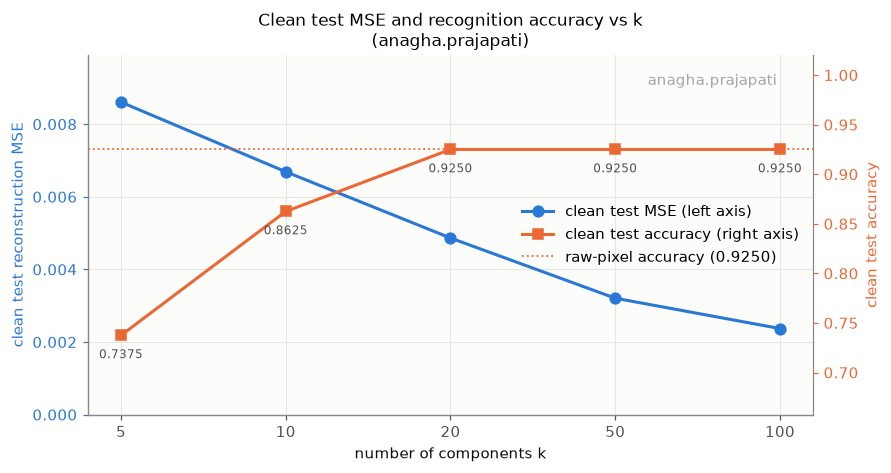

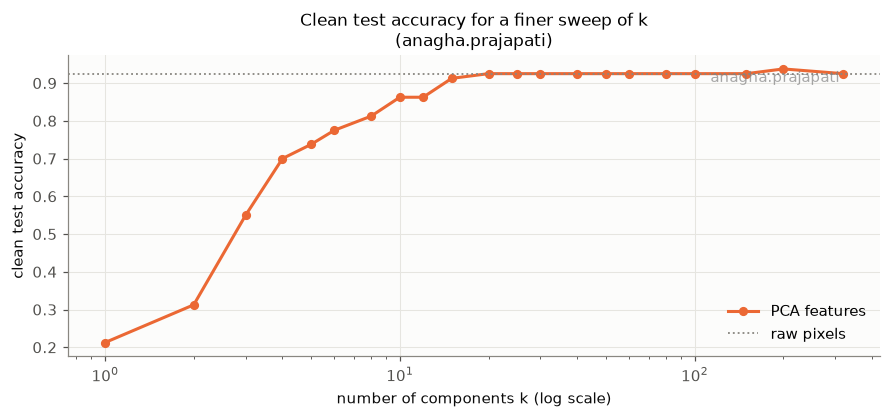

k        : [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 40, 50, 60, 80, 100, 150, 200, 319]
accuracy : [0.2125, 0.3125, 0.55, 0.7, 0.7375, 0.775, 0.8125, 0.8625, 0.8625, 0.9125, 0.925, 0.925, 0.925, 0.925, 0.925, 0.925, 0.925, 0.925, 0.925, 0.9375, 0.925]


In [19]:
fig, ax1 = plt.subplots(figsize=(8.2, 4.4))
xs = np.arange(len(K_VALUES))
l1, = ax1.plot(xs, [mse_k[k] for k in K_VALUES], "o-", color=BLUE, label="clean test MSE (left axis)")
ax1.set_xticks(xs, [str(k) for k in K_VALUES])
ax1.set_xlabel("number of components k")
ax1.set_ylabel("clean test reconstruction MSE", color=BLUE)
ax1.tick_params(axis="y", colors=BLUE)
ax1.set_ylim(0, max(mse_k.values()) * 1.15)
ax2 = ax1.twinx()
ax2.set_label("twin")   # second y-axis of the same plot: no second watermark
ax2.spines["right"].set_visible(True)
ax2.grid(False)
l2, = ax2.plot(xs, [acc_pca[k] for k in K_VALUES], "s-", color=ORANGE, label="clean test accuracy (right axis)")
l3 = ax2.axhline(acc_raw, color=ORANGE, lw=1.2, ls=":", label=f"raw-pixel accuracy ({acc_raw:.4f})")
for x_, k in zip(xs, K_VALUES):
    ax2.annotate(f"{acc_pca[k]:.4f}", (x_, acc_pca[k]), textcoords="offset points", xytext=(0, -15), ha="center",
                 fontsize=8, color=INK2)
ax2.set_ylabel("clean test accuracy", color=ORANGE)
ax2.tick_params(axis="y", colors=ORANGE)
ax2.set_ylim(min(acc_pca.values()) - 0.08, 1.02)
ax1.legend(handles=[l1, l2, l3], loc="center right")
titled(ax1, "Clean test MSE and recognition accuracy vs k")
finish(fig, "4_mse_and_accuracy")

# finer sweep (extra): accuracy for many k
K_FINE = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 40, 50, 60, 80, 100, 150, 200, 319]
acc_fine = [pca_accuracy(pca, X_train, X_test, k) for k in K_FINE]
fig, ax = plt.subplots(figsize=(8.2, 3.9))
ax.plot(K_FINE, acc_fine, "o-", color=ORANGE, markersize=5, label="PCA features")
ax.axhline(acc_raw, color=MUTED, lw=1.2, ls=":", label="raw pixels")
ax.set_xscale("log")
ax.set_xlabel("number of components k (log scale)")
ax.set_ylabel("clean test accuracy")
ax.legend(loc="lower right")
titled(ax, "Clean test accuracy for a finer sweep of k")
finish(fig, "4_accuracy_fine_sweep")
print("k        :", K_FINE)
print("accuracy :", [round(a, 4) for a in acc_fine])

**Clean accuracy.** Raw pixels give 92.50% (74 of 80 test faces). PCA features give 73.75% at k = 5, 86.25% at k = 10 and **92.50% at k = 20, 50 and 100**, the same as raw pixels. So 20 numbers per face recognise as well as 4,096 pixels. One test face is worth 1.25 percentage points, so differences of one or two faces should not be over-interpreted.

**Does lower MSE always mean higher accuracy? No.**

* From k = 5 to k = 20 both move together: MSE falls and accuracy rises. Here the added components carry information that separates people.
* From k = 20 to k = 100 the MSE falls by half (0.0049 → 0.0024) but accuracy does **not change at all** (92.50%). The finer sweep shows the same plateau from k = 20 to k = 150. The detail added by components 21 to 100 improves the picture but does not change which training face is nearest.
* Lower MSE can even come with **lower** accuracy: k = 319 has the lowest possible MSE of this PCA, yet its accuracy (92.50%) is one face below k = 200 (93.75%).
* The transformed sets make the point more strongly (Section 2.6): the noisy test set with σ = 0.2 has a reconstruction MSE 12 times the clean value and still reaches 90% accuracy, while the illuminated set has an MSE only 1.9 times the clean value and reaches 26%.

**Why.** MSE measures how faithfully **every pixel** is reproduced. Recognition only needs the directions in which **different people differ**, and it needs the differences between people to be large compared with the differences between images of the same person. PCA ranks directions by total variance, which mixes both kinds. The leading components carry enough between-person variation for the nearest-neighbour decision; the later ones mostly refine texture and image-specific detail that the Euclidean distance hardly uses. MSE is therefore a measure of compression quality, not of recognition quality.

## 2.4.3 Accuracy under rotation and noise at $k_T = 50$

The PCA and the classifier are fitted on the **clean training set**. Only the test faces are transformed. For reference, the dotted line shows the same classifier on raw pixels.

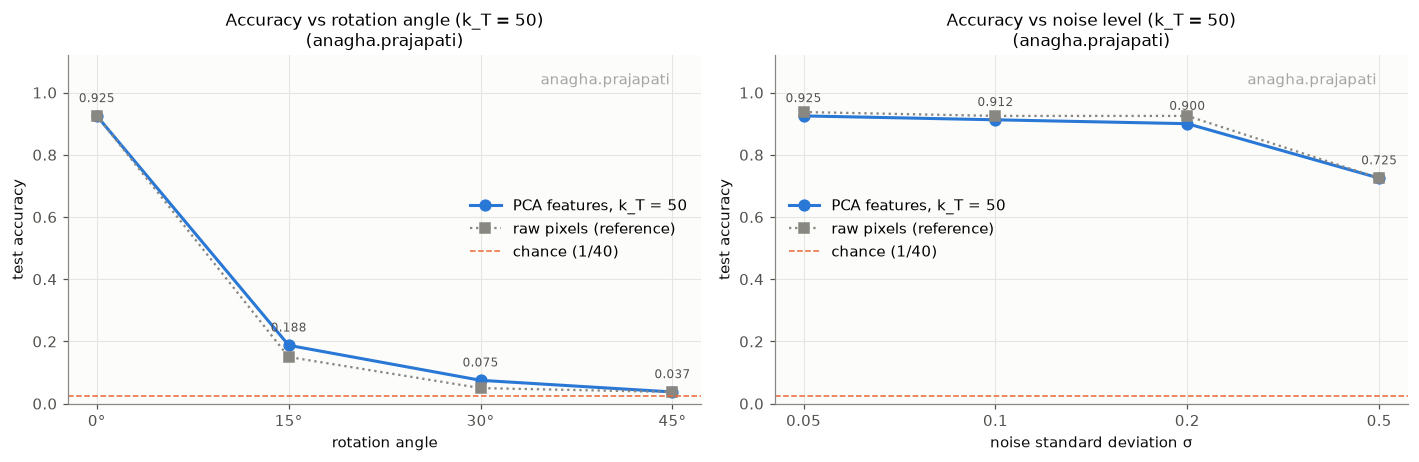

,"accuracy, PCA k_T=50","accuracy, raw pixels"
test set,,
rotation 0°,0.9250,0.9250
rotation 15°,0.1875,0.1500
rotation 30°,0.0750,0.0500
rotation 45°,0.0375,0.0375
noise sigma=0.05,0.9250,0.9375
noise sigma=0.1,0.9125,0.9250
noise sigma=0.2,0.9000,0.9250
noise sigma=0.5,0.7250,0.7250


clean test accuracy at k_T = 50: 0.9250


In [20]:
acc_clean_kT = pca_accuracy(pca, X_train, X_test, K_T)
acc_rot = {a: pca_accuracy(pca, X_train, X_rot[a], K_T) for a in ANGLES}
acc_noise = {s: pca_accuracy(pca, X_train, X_noise[s], K_T) for s in SIGMAS}
acc_rot_raw = {a: recognition_accuracy(X_train, y_train, X_rot[a], y_test) for a in ANGLES}
acc_noise_raw = {s: recognition_accuracy(X_train, y_train, X_noise[s], y_test) for s in SIGMAS}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
ax.plot(ANGLES, [acc_rot[a] for a in ANGLES], "o-", color=BLUE, label=f"PCA features, k_T = {K_T}")
ax.plot(ANGLES, [acc_rot_raw[a] for a in ANGLES], "s:", color=MUTED, lw=1.5, label="raw pixels (reference)")
for a in ANGLES:
    ax.annotate(f"{acc_rot[a]:.3f}", (a, acc_rot[a]), textcoords="offset points", xytext=(0, 9), ha="center",
                fontsize=8, color=INK2)
ax.axhline(1 / 40, color=ORANGE, lw=1, ls="--", label="chance (1/40)")
ax.set_xticks(ANGLES, [f"{a}°" for a in ANGLES])
ax.set_xlabel("rotation angle")
ax.set_ylabel("test accuracy")
ax.set_ylim(0, 1.12)
ax.legend(loc="center right")
titled(ax, f"Accuracy vs rotation angle (k_T = {K_T})")
ax = axes[1]
xs = np.arange(len(SIGMAS))
ax.plot(xs, [acc_noise[s] for s in SIGMAS], "o-", color=BLUE, label=f"PCA features, k_T = {K_T}")
ax.plot(xs, [acc_noise_raw[s] for s in SIGMAS], "s:", color=MUTED, lw=1.5, label="raw pixels (reference)")
for x_, s in zip(xs, SIGMAS):
    ax.annotate(f"{acc_noise[s]:.3f}", (x_, acc_noise[s]), textcoords="offset points", xytext=(0, 9), ha="center",
                fontsize=8, color=INK2)
ax.axhline(1 / 40, color=ORANGE, lw=1, ls="--", label="chance (1/40)")
ax.set_xticks(xs, [str(s) for s in SIGMAS])
ax.set_xlabel("noise standard deviation σ")
ax.set_ylabel("test accuracy")
ax.set_ylim(0, 1.12)
ax.legend(loc="center left")
titled(ax, f"Accuracy vs noise level (k_T = {K_T})")
finish(fig, "4_accuracy_rotation_noise")

robust_table = pd.DataFrame(
    [{"test set": f"rotation {a}°", f"accuracy, PCA k_T={K_T}": acc_rot[a], "accuracy, raw pixels": acc_rot_raw[a]} for a in ANGLES]
    + [{"test set": f"noise sigma={s}", f"accuracy, PCA k_T={K_T}": acc_noise[s], "accuracy, raw pixels": acc_noise_raw[s]} for s in SIGMAS]
).set_index("test set")
display(fmt(robust_table).format("{:.4f}"))
print(f"clean test accuracy at k_T = {K_T}: {acc_clean_kT:.4f}")

## 2.4.4 Illumination at $k_T = 50$

Three settings are compared:
* **(a)** PCA and classifier fitted on the clean training set, tested on the **clean** test set;
* **(b)** the same clean PCA and classifier, tested on the **illuminated** test set;
* **(c)** PCA **and** classifier refitted on the **illuminated training set**, tested on the illuminated test set.

In [21]:
pca_illum = PCAFromScratch("gram_trick").fit(X_train_illum)        # fitted on the illuminated TRAINING set only
acc_a = pca_accuracy(pca, X_train, X_test, K_T)
acc_b = pca_accuracy(pca, X_train, X_test_illum, K_T)
acc_c = pca_accuracy(pca_illum, X_train_illum, X_test_illum, K_T)
mse_c = reconstruction_mse(X_test_illum, reconstruct(pca_illum, X_test_illum, K_T))

illum_acc_table = pd.DataFrame([
    {"setting": "(a)", "PCA + classifier fitted on": "clean training set", "tested on": "clean test set",
     "accuracy": acc_a, "correct (of 80)": int(round(acc_a * 80)), "test MSE at k_T": mse_clean_kT},
    {"setting": "(b)", "PCA + classifier fitted on": "clean training set", "tested on": "illuminated test set",
     "accuracy": acc_b, "correct (of 80)": int(round(acc_b * 80)), "test MSE at k_T": mse_illum},
    {"setting": "(c)", "PCA + classifier fitted on": "illuminated training set", "tested on": "illuminated test set",
     "accuracy": acc_c, "correct (of 80)": int(round(acc_c * 80)), "test MSE at k_T": mse_c},
]).set_index("setting")
display(fmt(illum_acc_table).format("{:.4f}", subset=["accuracy"]).format("{:.5f}", subset=["test MSE at k_T"]))
print(f"variance explained by the first component: clean PCA {100 * pca.explained_variance_ratio_[0]:.1f}%, "
      f"illuminated PCA {100 * pca_illum.explained_variance_ratio_[0]:.1f}%")

,PCA + classifier fitted on,tested on,accuracy,correct (of 80),test MSE at k_T
setting,,,,,
(a),clean training set,clean test set,0.9250,74,0.00321
(b),clean training set,illuminated test set,0.2625,21,0.00608
(c),illuminated training set,illuminated test set,0.8125,65,0.00317


variance explained by the first component: clean PCA 23.1%, illuminated PCA 28.0%


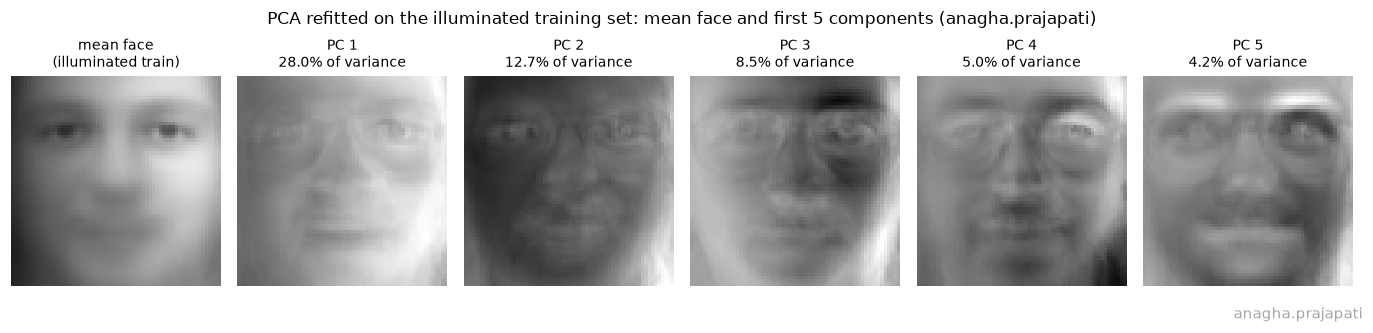

In [22]:
# the first eigenfaces of the PCA refitted on the illuminated training set (to see what it has learned)
fig, axes = plt.subplots(1, 6, figsize=(12.5, 2.9))
show_face(axes[0], pca_illum.mean_, "mean face\n(illuminated train)")
for i in range(5):
    comp = pca_illum.components_[i]
    lim = np.abs(comp).max()
    show_face(axes[i + 1], comp, f"PC {i + 1}\n{100 * pca_illum.explained_variance_ratio_[i]:.1f}% of variance", vmin=-lim, vmax=lim)
fig.suptitle(f"PCA refitted on the illuminated training set: mean face and first 5 components ({USERNAME})", fontsize=11)
finish(fig, "4_illuminated_eigenfaces")

**Rotation (2.4.3).** Accuracy collapses from 92.50% at 0° to 18.75% at 15°, 7.50% at 30° and 3.75% at 45°; chance level is 2.5%. Even 15° loses 59 of the 74 faces that were recognised. PCA coordinates are linear functions of the pixels at **fixed positions**. After a rotation the eyes, nose and mouth are at different pixel positions, so the coordinates change completely, and the nearest training face is determined by the black corners and the tilted layout, not by identity. Raw pixels fail in the same way (15.0%, 5.0%, 3.75%), which shows that the problem is the misalignment itself and not the compression.

**Noise (2.4.3).** Accuracy is almost unaffected by moderate noise: 92.50% at σ = 0.05, 91.25% at σ = 0.1 and 90.00% at σ = 0.2. Only the extreme σ = 0.5, where the face is barely visible to the eye, brings it down to 72.50%. Independent pixel noise is spread over all 4,096 directions and only about 1.2% of its energy falls into the 50-dimensional subspace, so the PCA coordinates barely move. Raw pixels are just as robust here (93.75%, 92.50%, 92.50%, 72.50%): the nearest-neighbour distance sums over 4,096 pixels, and the noise adds nearly the same amount to the distance to every training face, so the ranking of neighbours is preserved. PCA therefore gives no accuracy advantage under noise in this experiment; its advantage is that it achieves the same robustness with 50 numbers instead of 4,096.

**Illumination (2.4.4).**

| setting | fitted on | tested on | accuracy |
|---|---|---|---|
| (a) | clean training set | clean test set | 92.50% (74/80) |
| (b) | clean training set | illuminated test set | 26.25% (21/80) |
| (c) | illuminated training set | illuminated test set | 81.25% (65/80) |

* **(a) → (b): accuracy falls by 66 points**, although the reconstruction MSE only doubles. A brightness gradient is a smooth, high-energy pattern, and the leading eigenfaces encode exactly such lighting patterns (2.2.3). The gradient therefore moves a face a long way **inside** the PCA subspace, along the highest-variance components, which dominate the Euclidean distance. The shift caused by lighting is larger than the distance between different people, so the nearest clean training face is usually the wrong person.
* **(b) → (c): refitting recovers most of the loss** (26.25% → 81.25%). When the training faces are illuminated too, the gradient is part of the training variation: the mean face becomes darker on the left and brighter on the right, and a lopsided brightness pattern, brighter on one side of the image than on the other, appears among the leading components (PC 3 in the figure above). Training and test faces now vary in the same way, and each test face can find an enrolled face of the same person with a similar gradient. The test MSE also returns to the clean level (0.00317).
* **(c) stays below (a)** (81.25% vs 92.50%). Each image has its own random strength $s$, so the 8 enrolled images of one person now differ in lighting as well, which increases the variation within a person relative to the variation between people. Clipping also destroys information on the bright side of strongly lit faces.

---
# 2.5 Choosing k for SecureVision

`recommend_k` receives the clean test results for each candidate k. A k **qualifies** when

* its accuracy is at least `max(accuracy) - max_accuracy_drop`, **and**
* its compression ratio is at least `min_ratio`.

The function returns the **smallest** qualifying k, or `None`. The MSE is passed in so that the caller can report it; it does not take part in the decision. A tolerance of $10^{-12}$ protects the accuracy comparison against floating-point rounding (for example 0.95 − 0.02 is not exactly 0.93 in binary).

In [23]:
def recommend_k(k_values, mse, accuracy, ratio, max_accuracy_drop, min_ratio):
    """Return the smallest qualifying k, or None if no k qualifies."""
    accuracy_floor = max(accuracy) - max_accuracy_drop
    qualifying = [k for k, a, r in zip(k_values, accuracy, ratio)
                  if a >= accuracy_floor - 1e-12 and r >= min_ratio]
    return min(qualifying) if qualifying else None


def explain_recommendation(max_accuracy_drop, min_ratio):
    """Run recommend_k on the clean test results and show which condition every k passes or fails."""
    mse = [mse_k[k] for k in K_VALUES]
    acc = [acc_pca[k] for k in K_VALUES]
    ratio = [ratio_k[k] for k in K_VALUES]
    chosen = recommend_k(K_VALUES, mse, acc, ratio, max_accuracy_drop, min_ratio)
    floor = max(acc) - max_accuracy_drop
    table = pd.DataFrame({"k": K_VALUES, "MSE": mse, "accuracy": acc, "ratio": ratio,
                          f"accuracy >= {floor:.4f}": ["pass" if a >= floor - 1e-12 else "FAIL" for a in acc],
                          f"ratio >= {min_ratio}": ["pass" if r >= min_ratio else "FAIL" for r in ratio]}).set_index("k")
    table["qualifies"] = ["yes" if (a >= floor - 1e-12 and r >= min_ratio) else "no" for a, r in zip(acc, ratio)]
    print(f"max_accuracy_drop = {max_accuracy_drop}, min_ratio = {min_ratio}  ->  "
          f"accuracy floor = max(accuracy) - drop = {max(acc):.4f} - {max_accuracy_drop} = {floor:.4f}")
    display(fmt(table).format("{:.5f}", subset=["MSE"]).format("{:.4f}", subset=["accuracy"]).format("{:.2f}", subset=["ratio"]))
    if chosen is None:
        print("recommended k: None (no k qualifies)\n")
    else:
        print(f"recommended k = {chosen}:  MSE = {mse_k[chosen]:.5f},  accuracy = {acc_pca[chosen]:.4f},  "
              f"compression ratio = {ratio_k[chosen]:.2f}\n")
    return chosen


# unit checks of the function on hand-made inputs
assert recommend_k([5, 10, 20], [3, 2, 1], [0.80, 0.95, 0.96], [50, 27, 14], 0.02, 10) == 10
assert recommend_k([5, 10, 20], [3, 2, 1], [0.80, 0.95, 0.96], [50, 27, 14], 0.02, 30) is None
assert recommend_k([5, 10, 20], [3, 2, 1], [0.80, 0.95, 0.96], [50, 27, 14], 0.20, 10) == 5
print("recommend_k passes the hand-made checks.\n")

recommend_k passes the hand-made checks.



## 2.5.1 Recommendation with `max_accuracy_drop = 0.02` and `min_ratio = 10`

In [24]:
k_base = explain_recommendation(max_accuracy_drop=0.02, min_ratio=10)

max_accuracy_drop = 0.02, min_ratio = 10  ->  accuracy floor = max(accuracy) - drop = 0.9250 - 0.02 = 0.9050


,MSE,accuracy,ratio,accuracy >= 0.9050,ratio >= 10,qualifies
k,,,,,,
5,0.00861,0.7375,50.07,FAIL,pass,no
10,0.00669,0.8625,27.16,FAIL,pass,no
20,0.00486,0.9250,14.18,pass,pass,yes
50,0.00321,0.9250,5.83,pass,FAIL,no
100,0.00237,0.9250,2.94,pass,FAIL,no


recommended k = 20:  MSE = 0.00486,  accuracy = 0.9250,  compression ratio = 14.18



## 2.5.2 Changing one threshold

Each run below changes **one** threshold of the base setting and keeps the other. The main change is `min_ratio` 10 → 5 (a looser storage requirement). Three further single-threshold changes are run as well, to show when the recommendation does move.

In [25]:
print("=== MAIN CHANGE: min_ratio 10 -> 5 (accuracy threshold unchanged) ===")
k_ratio5 = explain_recommendation(max_accuracy_drop=0.02, min_ratio=5)

print("--- further single-threshold changes, for comparison ---")
print()
print("=== min_ratio 10 -> 20 (accuracy threshold unchanged) ===")
k_ratio20 = explain_recommendation(max_accuracy_drop=0.02, min_ratio=20)
print("=== max_accuracy_drop 0.02 -> 0.05 (ratio threshold unchanged) ===")
k_drop5 = explain_recommendation(max_accuracy_drop=0.05, min_ratio=10)
print("=== max_accuracy_drop 0.02 -> 0.07 (ratio threshold unchanged) ===")
k_drop7 = explain_recommendation(max_accuracy_drop=0.07, min_ratio=10)

=== MAIN CHANGE: min_ratio 10 -> 5 (accuracy threshold unchanged) ===
max_accuracy_drop = 0.02, min_ratio = 5  ->  accuracy floor = max(accuracy) - drop = 0.9250 - 0.02 = 0.9050


,MSE,accuracy,ratio,accuracy >= 0.9050,ratio >= 5,qualifies
k,,,,,,
5,0.00861,0.7375,50.07,FAIL,pass,no
10,0.00669,0.8625,27.16,FAIL,pass,no
20,0.00486,0.9250,14.18,pass,pass,yes
50,0.00321,0.9250,5.83,pass,pass,yes
100,0.00237,0.9250,2.94,pass,FAIL,no


recommended k = 20:  MSE = 0.00486,  accuracy = 0.9250,  compression ratio = 14.18

--- further single-threshold changes, for comparison ---

=== min_ratio 10 -> 20 (accuracy threshold unchanged) ===
max_accuracy_drop = 0.02, min_ratio = 20  ->  accuracy floor = max(accuracy) - drop = 0.9250 - 0.02 = 0.9050


,MSE,accuracy,ratio,accuracy >= 0.9050,ratio >= 20,qualifies
k,,,,,,
5,0.00861,0.7375,50.07,FAIL,pass,no
10,0.00669,0.8625,27.16,FAIL,pass,no
20,0.00486,0.9250,14.18,pass,FAIL,no
50,0.00321,0.9250,5.83,pass,FAIL,no
100,0.00237,0.9250,2.94,pass,FAIL,no


recommended k: None (no k qualifies)

=== max_accuracy_drop 0.02 -> 0.05 (ratio threshold unchanged) ===
max_accuracy_drop = 0.05, min_ratio = 10  ->  accuracy floor = max(accuracy) - drop = 0.9250 - 0.05 = 0.8750


,MSE,accuracy,ratio,accuracy >= 0.8750,ratio >= 10,qualifies
k,,,,,,
5,0.00861,0.7375,50.07,FAIL,pass,no
10,0.00669,0.8625,27.16,FAIL,pass,no
20,0.00486,0.9250,14.18,pass,pass,yes
50,0.00321,0.9250,5.83,pass,FAIL,no
100,0.00237,0.9250,2.94,pass,FAIL,no


recommended k = 20:  MSE = 0.00486,  accuracy = 0.9250,  compression ratio = 14.18

=== max_accuracy_drop 0.02 -> 0.07 (ratio threshold unchanged) ===
max_accuracy_drop = 0.07, min_ratio = 10  ->  accuracy floor = max(accuracy) - drop = 0.9250 - 0.07 = 0.8550


,MSE,accuracy,ratio,accuracy >= 0.8550,ratio >= 10,qualifies
k,,,,,,
5,0.00861,0.7375,50.07,FAIL,pass,no
10,0.00669,0.8625,27.16,pass,pass,yes
20,0.00486,0.9250,14.18,pass,pass,yes
50,0.00321,0.9250,5.83,pass,FAIL,no
100,0.00237,0.9250,2.94,pass,FAIL,no


recommended k = 10:  MSE = 0.00669,  accuracy = 0.8625,  compression ratio = 27.16



**2.5.1 Base setting (`max_accuracy_drop = 0.02`, `min_ratio = 10`).**
The best clean accuracy is 0.9250, so the accuracy floor is 0.9050.

| k | accuracy ≥ 0.9050 ? | ratio ≥ 10 ? | qualifies |
|---|---|---|---|
| 5 | no (0.7375) | yes (50.07) | no |
| 10 | no (0.8625) | yes (27.16) | no |
| **20** | **yes (0.9250)** | **yes (14.18)** | **yes** |
| 50 | yes (0.9250) | no (5.83) | no |
| 100 | yes (0.9250) | no (2.94) | no |

> **Recommended k = 20: MSE = 0.00486, accuracy = 0.9250, compression ratio = 14.18.**

k = 20 is the only candidate that satisfies both conditions. Smaller k fail the accuracy condition; larger k fail the storage condition. With k = 20 the lock stores 92,416 values instead of 1,310,720 and recognises exactly as well as with raw pixels.

**2.5.2 Changing one threshold.**

* **Main change: `min_ratio` 10 → 5. The recommendation does not change (k = 20).** Loosening the storage requirement lets k = 50 qualify as well (ratio 5.83 ≥ 5), so there are now two qualifying values, 20 and 50. The function returns the **smallest** qualifying k, and k = 20 still qualifies, so the answer stays 20. Relaxing a constraint can only add candidates; it changes the answer only if a newly admitted k is smaller than the current one. Here the ratio threshold only ever excludes *large* k, and a looser threshold admits larger k, so it cannot lower the recommendation.
* *`min_ratio` 10 → 20: the recommendation becomes `None`.* k = 20 has a ratio of 14.18 and now fails. The only values that compress by 20 times or more are k = 5 and k = 10, and both fail the accuracy condition. The two requirements cannot be met together with these candidates.
* *`max_accuracy_drop` 0.02 → 0.05: no change (k = 20).* The floor drops to 0.8750, but k = 10 has 0.8625 and still fails, so k = 20 remains the smallest qualifying value.
* *`max_accuracy_drop` 0.02 → 0.07: the recommendation changes to k = 10.* The floor drops to 0.8550, and k = 10 (0.8625) now passes both conditions. Being smaller than 20, it becomes the recommendation: compression ratio 27.16 instead of 14.18, at the price of 5 more misidentified faces out of 80 (accuracy 0.8625 instead of 0.9250).

**In summary:** the accuracy threshold decides the *lower* end of the admissible range of k and the ratio threshold the *upper* end. Because the smallest qualifying k is returned, the recommendation moves only when the accuracy threshold admits a smaller k, or when the ratio threshold removes the current one. For a door lock, k = 20 is the sensible choice: accepting 6 more points of error to save storage would not be justified for a security device.

---
# 2.6 Where PCA Breaks

The table collects the results at $k_T = 50$ with the PCA and classifier fitted on the clean training set. "MSE" is the reconstruction error of the transformed face against its own reconstruction (the quantity plotted in 2.3.4); for noise the MSE against the clean face is shown as well.

In [26]:
rows = [{"test set": "clean", "MSE (face vs its reconstruction)": mse_clean_kT, "accuracy": acc_clean_kT}]
rows += [{"test set": f"rotation {a}°", "MSE (face vs its reconstruction)": mse_rot[a], "accuracy": acc_rot[a]} for a in ANGLES]
mse_noisy_self = {s: reconstruction_mse(X_noise[s], reconstruct(pca, X_noise[s], K_T)) for s in SIGMAS}
rows += [{"test set": f"noise sigma={s}", "MSE (face vs its reconstruction)": mse_noisy_self[s], "accuracy": acc_noise[s],
          "MSE (reconstruction vs clean face)": mse_recon_vs_clean[s]} for s in SIGMAS]
rows += [{"test set": "illumination", "MSE (face vs its reconstruction)": mse_illum, "accuracy": acc_b}]
breaks = pd.DataFrame(rows).set_index("test set")
breaks["MSE / clean MSE"] = breaks["MSE (face vs its reconstruction)"] / mse_clean_kT
breaks["MSE increased?"] = np.where(breaks["MSE (face vs its reconstruction)"] > mse_clean_kT * (1 + 1e-9), "yes", "no")
breaks["accuracy change"] = breaks["accuracy"] - acc_clean_kT
breaks["accuracy reduced?"] = np.where(breaks["accuracy"] < acc_clean_kT - 1e-12, "yes", "no")
breaks.loc["clean", ["MSE increased?", "accuracy reduced?"]] = "-"
breaks["MSE (reconstruction vs clean face)"] = breaks["MSE (reconstruction vs clean face)"].map(
    lambda v: "" if pd.isna(v) else f"{v:.5f}")
breaks = breaks[["MSE (face vs its reconstruction)", "MSE / clean MSE", "MSE increased?",
                 "MSE (reconstruction vs clean face)", "accuracy", "accuracy change", "accuracy reduced?"]]
display(fmt(breaks).format("{:.5f}", subset=["MSE (face vs its reconstruction)"]).format("{:.2f}", subset=["MSE / clean MSE"])
        .format("{:.4f}", subset=["accuracy"]).format("{:+.4f}", subset=["accuracy change"]))

,MSE (face vs its reconstruction),MSE / clean MSE,MSE increased?,MSE (reconstruction vs clean face),accuracy,accuracy change,accuracy reduced?
test set,,,,,,,
clean,0.00321,1.00,-,,0.9250,+0.0000,-
rotation 0°,0.00321,1.00,no,,0.9250,+0.0000,no
rotation 15°,0.02008,6.26,yes,,0.1875,-0.7375,yes
rotation 30°,0.02366,7.38,yes,,0.0750,-0.8500,yes
rotation 45°,0.02291,7.14,yes,,0.0375,-0.8875,yes
noise sigma=0.05,0.00565,1.76,yes,0.00324,0.9250,+0.0000,no
noise sigma=0.1,0.01291,4.03,yes,0.00333,0.9125,-0.0125,yes
noise sigma=0.2,0.03850,12.00,yes,0.00372,0.9000,-0.0250,yes
noise sigma=0.5,0.12092,37.70,yes,0.00803,0.7250,-0.2000,yes


**Summary at $k_T = 50$** (clean test set: MSE 0.00321, accuracy 92.50%).

| transformation | MSE increased? | accuracy reduced? |
|---|---|---|
| rotation 15°, 30°, 45° | **yes**, 6.3 to 7.4 times the clean MSE | **yes**, to 18.75%, 7.50%, 3.75% |
| noise σ = 0.05 | **yes**, 1.8 times (face vs its reconstruction) | **no**, 92.50% |
| noise σ = 0.1, 0.2 | **yes**, 4 and 12 times | **yes, slightly**, 91.25% and 90.00% (1 and 2 faces) |
| noise σ = 0.5 | **yes**, 38 times | **yes**, 72.50% |
| illumination | **yes**, 1.9 times | **yes**, to 26.25% |

(Rotation by 0° is the clean test set and changes nothing.)

The three transformations fail in three different ways, and the size of the MSE increase does **not** predict the loss of accuracy.

**Rotation: high MSE and accuracy destroyed.**
*Why.* PCA is a linear model of pixel intensities at fixed positions. It assumes that each pixel always shows the same part of the face. Rotation moves every facial feature to other pixels, which is a highly non-linear change in pixel space. The rotated face lies far from the eigenface subspace (high MSE), and its projection has nothing to do with the person (accuracy near chance).
*Fix.* **Align the face before PCA**: detect the two eyes, then rotate and scale the image so that the eyes are at fixed positions. This geometric normalisation removes the rotation before the eigenfaces see it. (An alternative is to enrol rotated copies of every face, which costs storage and only covers the angles included.)

**Noise: MSE increased the most, accuracy hardly affected.**
*Why.* Independent pixel noise is spread evenly over all 4,096 directions. Almost all of it is orthogonal to the 50-dimensional eigenface subspace, so it shows up as a very large error between the noisy face and its reconstruction (the reconstruction simply does not contain the noise). The coordinates used for recognition, however, receive only about 1.2% of the noise energy, and the reconstruction stays close to the *clean* face (0.0032 to 0.0037 for σ ≤ 0.2). Accuracy only suffers at σ = 0.5, where the noise is larger than the image contrast and clipping distorts the brightness of the whole image.
*Fix.* PCA projection is already a denoiser, so nothing more is needed for moderate noise. For heavy noise, **reduce the noise before projecting**: average several frames from the camera, or apply a small smoothing (Gaussian or median) filter to the image.

**Illumination: small MSE increase, accuracy destroyed.**
*Why.* A brightness gradient is smooth and global, exactly the kind of pattern the leading eigenfaces represent. The illuminated face is therefore reconstructed fairly well (MSE only 1.9 times higher), but its coordinates move a long way along the highest-variance components, further than the distance between different people. The representation is faithful, but the lighting, not the identity, decides the nearest neighbour.
*Fix.* **Normalise the lighting before PCA**, for example by histogram equalisation or by fitting and dividing out a smooth brightness plane from each image. Two alternatives are supported by results in this notebook or by standard practice: train on faces under varied lighting, which raised accuracy from 26.25% to 81.25% in setting (c); or discard the first few principal components, which mostly encode lighting.

**Lesson for SecureVision.** Eigenfaces give compact, noise-robust templates, but only for faces that are aligned and evenly lit. The lock needs an alignment step and a lighting-normalisation step in front of the PCA, or enrolment images that cover the lighting conditions at the door.

---
# Summary of results

In [27]:
summary = pd.DataFrame([
    {"item": "2.1 data", "result": f"{n_images} images, {H}x{W}, {len(identities)} identities; train {X_train.shape}, test {X_test.shape}; seed {SEED}"},
    {"item": "2.2 fit time", "result": f"direct {t_direct.mean():.2f} s vs gram_trick {t_gram.mean():.4f} s ({t_direct.mean() / t_gram.mean():.0f}x faster)"},
    {"item": "2.2 agreement (top 50)", "result": f"max |eigenvalue difference| {eig_diff.max():.1e}; min |correlation| {corr.min():.10f}"},
    {"item": "2.3 clean test MSE", "result": ", ".join(f"k={k}: {mse_test_curve[k - 1]:.5f}" for k in K_SHOW)},
    {"item": "2.3 compression ratio", "result": ", ".join(f"k={k}: {compression_ratio(N_STORE, D_STORE, k):.2f}" for k in K_SHOW)},
    {"item": "2.3 smallest k for 90% variance", "result": f"k = {k90}"},
    {"item": "2.4 clean accuracy", "result": f"raw {acc_raw:.4f}; " + ", ".join(f"k={k}: {acc_pca[k]:.4f}" for k in K_VALUES)},
    {"item": "2.4 rotation accuracy (k_T)", "result": ", ".join(f"{a}°: {acc_rot[a]:.4f}" for a in ANGLES)},
    {"item": "2.4 noise accuracy (k_T)", "result": ", ".join(f"σ={s}: {acc_noise[s]:.4f}" for s in SIGMAS)},
    {"item": "2.4 illumination accuracy (k_T)", "result": f"(a) {acc_a:.4f}, (b) {acc_b:.4f}, (c) {acc_c:.4f}"},
    {"item": "2.5 recommended k (drop 0.02, ratio 10)", "result": f"k = {k_base}"},
]).set_index("item")
with pd.option_context("display.max_colwidth", 200):
    display(summary)

,result
item,
2.1 data,"400 images, 64x64, 40 identities; train (320, 4096), test (80, 4096); seed 2679482985"
2.2 fit time,direct 19.78 s vs gram_trick 0.2147 s (92x faster)
2.2 agreement (top 50),max |eigenvalue difference| 1.1e-14; min |correlation| 1.0000000000
2.3 clean test MSE,"k=10: 0.00669, k=50: 0.00321, k=100: 0.00237"
2.3 compression ratio,"k=10: 27.16, k=50: 5.83, k=100: 2.94"
2.3 smallest k for 90% variance,k = 63
2.4 clean accuracy,"raw 0.9250; k=5: 0.7375, k=10: 0.8625, k=20: 0.9250, k=50: 0.9250, k=100: 0.9250"
2.4 rotation accuracy (k_T),"0°: 0.9250, 15°: 0.1875, 30°: 0.0750, 45°: 0.0375"
2.4 noise accuracy (k_T),"σ=0.05: 0.9250, σ=0.1: 0.9125, σ=0.2: 0.9000, σ=0.5: 0.7250"


---
### AI tool usage declaration

*(Required by the assignment if AI tools were used. Add a shareable link to, or a screenshot of, the AI conversation here, and briefly describe how you verified and modified the generated content. For example: the two PCA methods are checked against each other in 2.2.2, the components are checked for unit length and orthogonality, a full-rank reconstruction is checked to be exact, rotation by 0° is checked to return the original image, and `recommend_k` is checked on hand-made inputs.)*